<a href="https://colab.research.google.com/github/ArrigoniS/Churn_Rate_Project/blob/main/Fnergy_Analytics_Forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecast Analysis

## Project
Predict the short term electricity consumption to define the electricity supplies from the energy market.

#### Dataset Structure:
30 time series coming from 5000 buildings (houses, stores...) from 2009-2010 with every time series named cluster and row id that contains the date.
Every cluster or column is related to a specific type of building and contains the average consumption in KWh.

#### Clusters Analyzed:
1. cluster_26: that has daily (24h) and monthly (168h) seasonality with also clear differences between hours and between weekends and working days;
2. cluster_9: that has daily (24h) seasonality;
3. cluster_24: that doesn't have any seasonality and the time series it's flat without any time of structured variance.

## Steps for the analysis:
- **STEP 1:** Exploratory Analysis and data preparation. first visualization of the series, data cleaning (missing values, outlier), analysis of the moving average, feature engineering if needed and models preparation with timeframe window, normalization, split train/test.
- **STEP 2:** Classic models. AR(1) will be the baseline for the models. ACF/PACF analysis and appriopriated tests (stationarity, seasonality). ARIMA or SARIMA models for the three clusters in dependencies of the data preparation done before. Evaluation of the models with MAE, RMSE, MAPE and a visualization between prediction and real data on the test set.
- **STEP 3:** Recurrent models. LSTM network for the three clusters, Evaluation of the models with MAE, RMSE, MAPE and a visualization between prediction and real data on the test set.
- **STEP 4:** Hyperparameters optimization and comparison with the baseline (AR(1)) and between models with the same metrics define above.
- **STEP 5:** Conclusion. Diffirences between models for every cluster under analysis and definition of the best models between every cluster (if the baseline is better should be considered as the best model). Real scenario and possible use for the best model for every cluster and possible future implementation (hybrid models, multi-step forecasting, new feature)

In [ ]:
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns
import numpy as np
import warnings
import logging
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import itertools
from statsmodels.tools.sm_exceptions import ValueWarning
import matplotlib.dates as mdates

# Warning and Logger
warnings.filterwarnings("ignore")
logging.getLogger("statsmodels").setLevel(logging.ERROR)

# Plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 6)

# Dataset URL
url = "https://raw.githubusercontent.com/Profession-AI/progetti-ml/main/Previsione%20del%20Consumo%20Energetico%20con%20Modelli%20Classici%20e%20Ricorrenti/clustered_hourly_values_all.csv"
df = pd.read_csv(url)

# Preview and general info
print("Dataset Preview:")
display(df.head())
print("\nDataset Information:")
print(df.info())

Dataset Preview:


,row ID,cluster_11,cluster_28,cluster_24,cluster_1,cluster_12,cluster_2,cluster_23,cluster_26,cluster_21,...,cluster_14,cluster_20,cluster_4,cluster_8,cluster_7,cluster_22,cluster_25,cluster_9,cluster_15,cluster_3
0,2009-07-15_00,0.198786,18.358000,0.777450,2.488265,9.594552,0.462515,0.391711,3.254085,0.357386,...,0.897384,0.598728,0.920695,0.875265,0.845983,0.658726,1.382476,1.037702,1.090514,0.947526
1,2009-07-15_01,0.171071,16.028357,0.591275,2.747633,7.681776,0.260338,0.398816,3.197561,0.364500,...,0.612620,0.395499,0.561120,0.650493,0.587325,0.438029,0.972665,0.730954,0.781937,0.580975
2,2009-07-15_02,0.162000,15.065393,0.483900,2.497571,6.972241,0.296500,0.396171,3.038390,0.361659,...,0.490683,0.324087,0.426242,0.522865,0.499978,0.346501,0.696608,0.518665,0.595129,0.452213
3,2009-07-15_03,0.189571,15.304214,0.353325,2.404000,6.804086,0.247176,0.399645,3.029756,0.349489,...,0.457262,0.303519,0.376581,0.469952,0.462120,0.334346,0.563122,0.423768,0.531196,0.416438
4,2009-07-15_04,0.320929,15.284107,0.378625,2.156265,6.595086,0.252132,0.411039,3.005634,0.347057,...,0.447911,0.283072,0.359359,0.485992,0.463902,0.314235,0.535823,0.382569,0.502776,0.398079



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12838 entries, 0 to 12837
Data columns (total 31 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   row ID      12838 non-null  object 
 1   cluster_11  12838 non-null  float64
 2   cluster_28  12838 non-null  float64
 3   cluster_24  12838 non-null  float64
 4   cluster_1   12838 non-null  float64
 5   cluster_12  12838 non-null  float64
 6   cluster_2   12838 non-null  float64
 7   cluster_23  12838 non-null  float64
 8   cluster_26  12838 non-null  float64
 9   cluster_21  12838 non-null  float64
 10  cluster_13  12838 non-null  float64
 11  cluster_5   12838 non-null  float64
 12  cluster_18  12838 non-null  float64
 13  cluster_0   12838 non-null  float64
 14  cluster_29  12838 non-null  float64
 15  cluster_19  12838 non-null  float64
 16  cluster_6   12838 non-null  float64
 17  cluster_16  12838 non-null  float64
 18  cluster_27  12838 non-null  float64
 19  clu

In [ ]:
# Set datetime to index
df['row_id_clean'] = pd.to_datetime(df['row ID'], format='%Y-%m-%d_%H')
df.set_index('row_id_clean', inplace=True)

# Target clusters defined before
target_clusters = ['cluster_26', 'cluster_9', 'cluster_24']
df_target = df[target_clusters]

# Check for missing values
print("Missing values for each cluster:")
print(df_target.isnull().sum())

# Statistics
print("\nDescriptive Statistics:")
display(df_target.describe())

Missing values for each cluster:
cluster_26    0
cluster_9     0
cluster_24    0
dtype: int64

Descriptive Statistics:


,cluster_26,cluster_9,cluster_24
count,12838.000000,12838.000000,12838.000000
mean,7.210478,1.173191,0.707295
std,4.999290,0.627206,0.390985
min,2.457593,0.330619,0.135774
25%,3.548634,0.588801,0.410935
50%,4.470976,1.091933,0.592541
75%,10.925528,1.606156,0.921184
max,23.273883,3.571644,2.711129


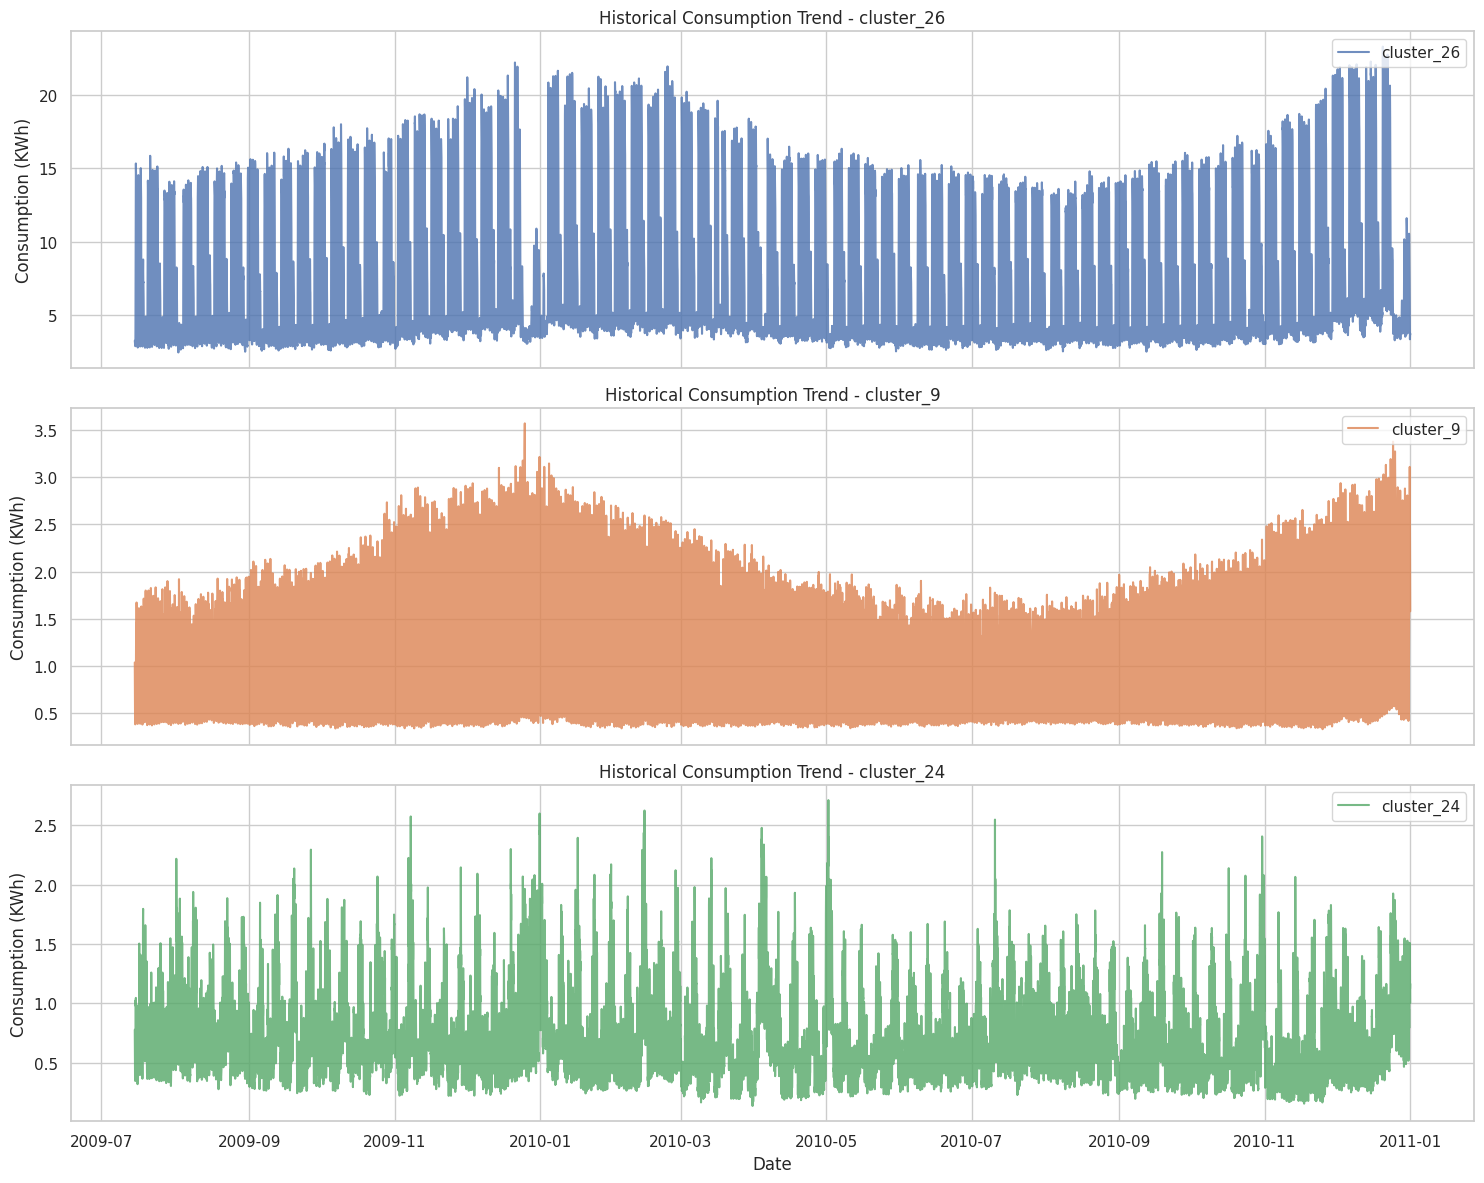

In [ ]:
# Visualize the complete time series for the three selected clusters
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

for i, col in enumerate(target_clusters):
    axes[i].plot(df_target.index, df_target[col], label=col, color=f"C{i}", alpha=0.8)
    axes[i].set_title(f"Historical Consumption Trend - {col}", fontsize=12)
    axes[i].set_ylabel("Consumption (KWh)")
    axes[i].legend(loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

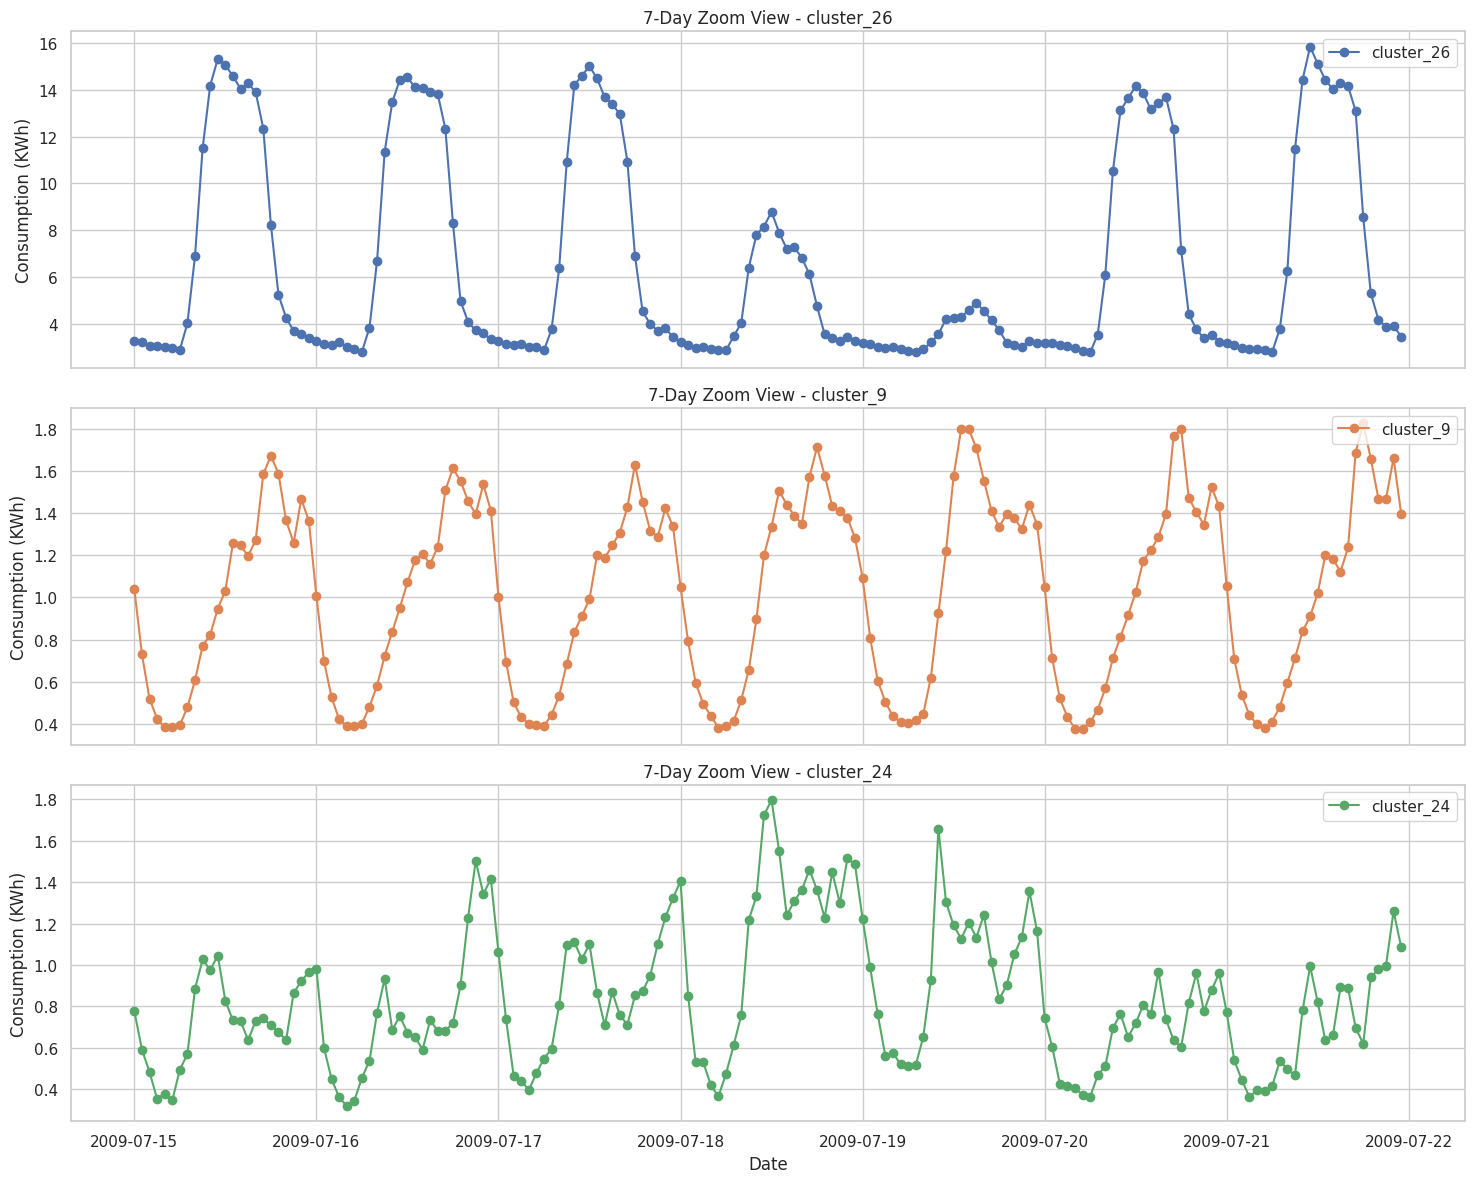

In [ ]:
# ZOOM IN: 7-day window to inspect daily and weekly seasonality patterns
weekly_zoom = df_target.first('7D')

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

for i, col in enumerate(target_clusters):
    axes[i].plot(weekly_zoom.index, weekly_zoom[col], marker='o', label=col, color=f"C{i}")
    axes[i].set_title(f"7-Day Zoom View - {col}", fontsize=12)
    axes[i].set_ylabel("Consumption (KWh)")
    axes[i].legend(loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

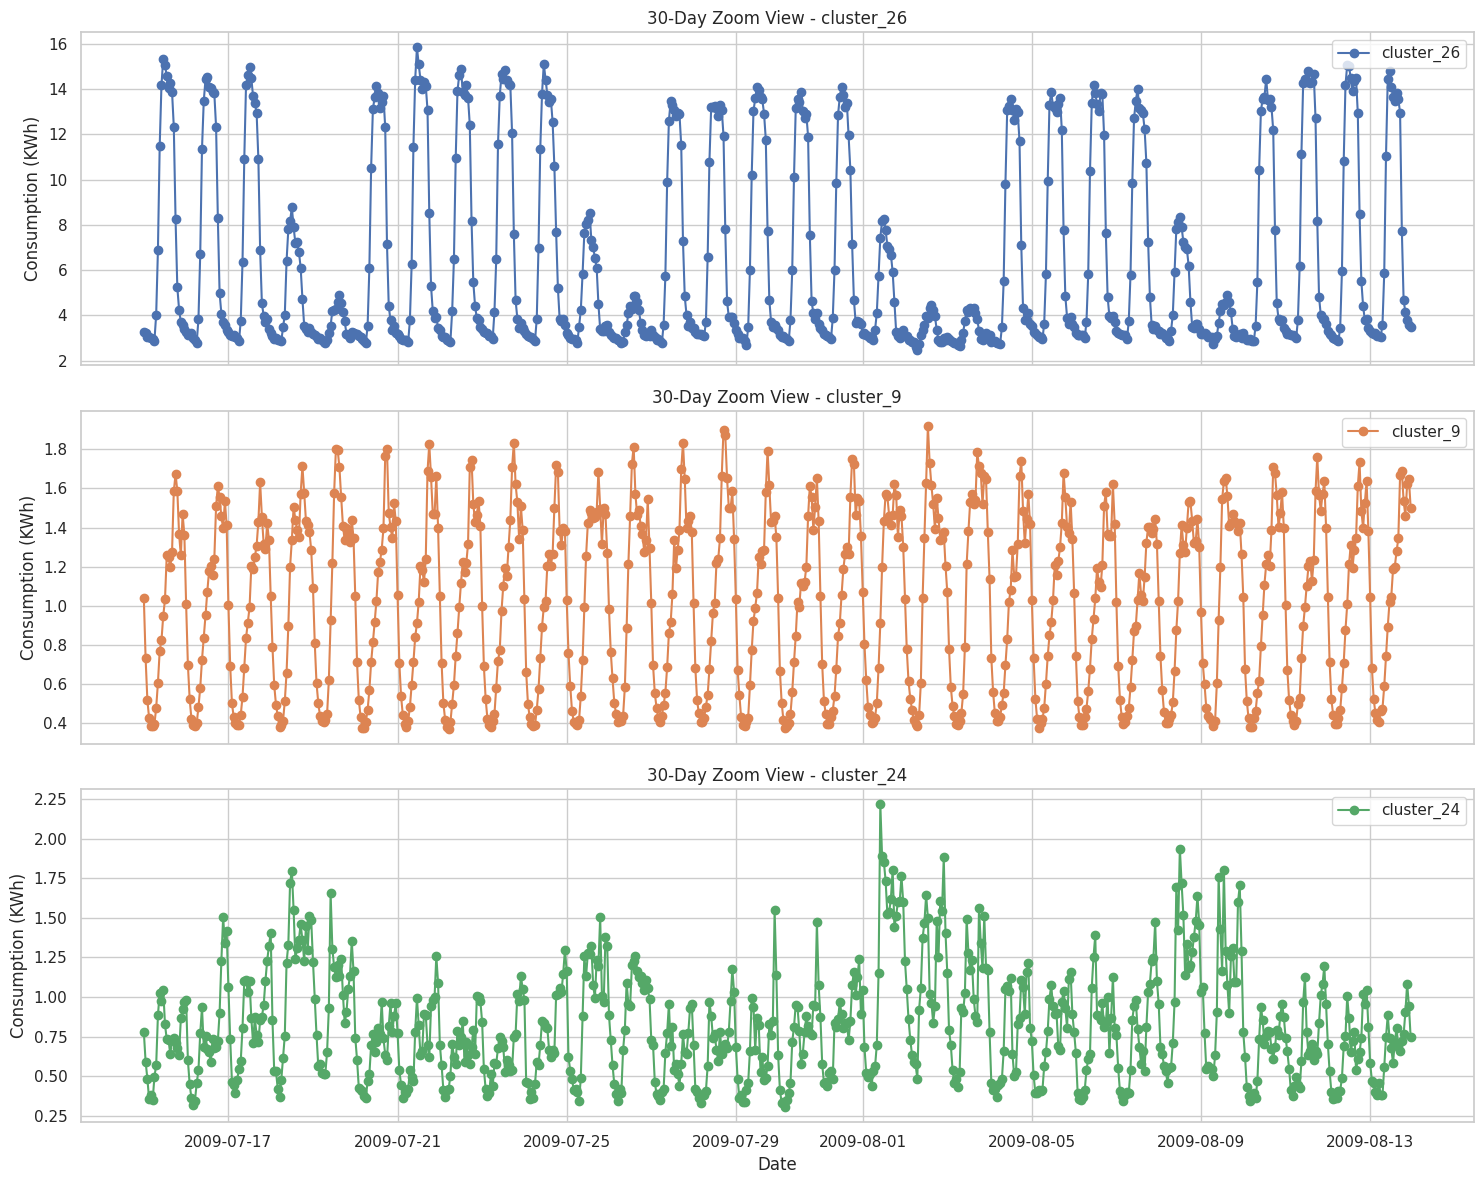

In [ ]:
# ZOOM IN: 60-day window to inspect monthly seasonality patterns
monthly_zoom = df_target.first('60D')

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

for i, col in enumerate(target_clusters):
    axes[i].plot(monthly_zoom.index, monthly_zoom[col], marker='o', label=col, color=f"C{i}")
    axes[i].set_title(f"30-Day Zoom View - {col}", fontsize=12)
    axes[i].set_ylabel("Consumption (KWh)")
    axes[i].legend(loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

##### Outlier Detection


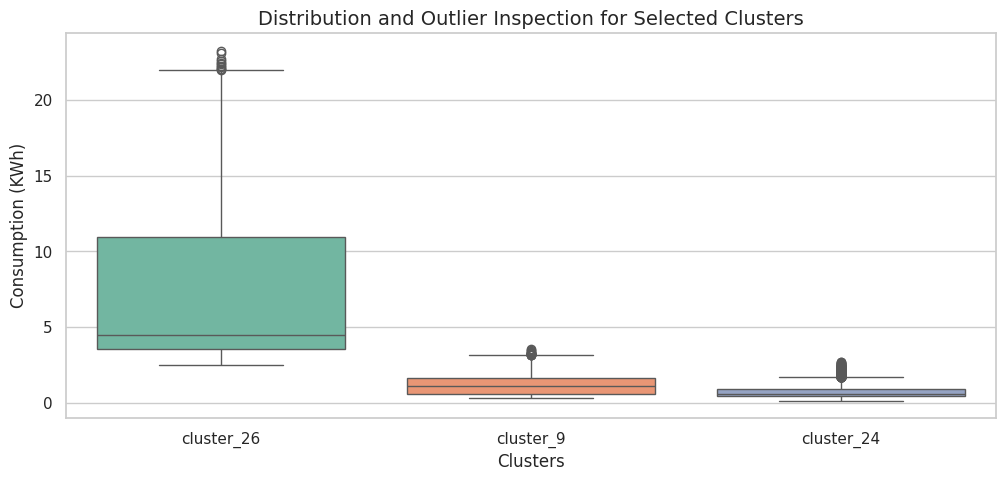

=== OUTLIER ANALYSIS BY DATE AND HOLIDAYS ===

--- Cluster: cluster_26 ---
Total outliers detected: 11 out of 12838 samples

Top 10 days of the year with the most outlier hours (Day-Month):
  - Date: 21-12 | Outlier hours: 3 -> (Christmas Period)
  - Date: 20-12 | Outlier hours: 3 -> (Christmas Period)
  - Date: 06-12 | Outlier hours: 1
  - Date: 09-12 | Outlier hours: 1
  - Date: 15-12 | Outlier hours: 1
  - Date: 17-12 | Outlier hours: 1
  - Date: 22-12 | Outlier hours: 1 -> (Christmas Period)

Distribution by Day of the Week:
Day_of_Week
Monday       5
Wednesday    2
Tuesday      2
Thursday     1
Friday       1
Name: count, dtype: int64


--- Cluster: cluster_9 ---
Total outliers detected: 15 out of 12838 samples

Top 10 days of the year with the most outlier hours (Day-Month):
  - Date: 25-12 | Outlier hours: 9 -> (Christmas Day)
  - Date: 24-12 | Outlier hours: 3 -> (Christmas Eve)
  - Date: 31-12 | Outlier hours: 1 -> (New Year's Day)
  - Date: 04-01 | Outlier hours: 1
  - Date: 

In [ ]:
# 1. Boxplot: distribution and outliers
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_target, palette="Set2")
plt.title("Distribution and Outlier Inspection for Selected Clusters", fontsize=14)
plt.ylabel("Consumption (KWh)")
plt.xlabel("Clusters")
plt.show()

# 2. Outlier Identification and Calendar Matching
print("=== OUTLIER ANALYSIS BY DATE AND HOLIDAYS ===\n")

for col in target_clusters:
    series = df_target[col]

    # Calculate boundaries using IQR
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identifying outliers: above upper bound or below lower bound
    outliers = series[(series > upper_bound) | (series < lower_bound)]

    print(f"--- Cluster: {col} ---")
    print(f"Total outliers detected: {len(outliers)} out of {len(series)} samples")

    if len(outliers) > 0:
        # Temporary DataFrame to analyze outlier dates
        df_outliers = pd.DataFrame({
            'Consumption_KWh': outliers,
            'Day_of_Week': outliers.index.day_name(),
            'Month': outliers.index.month,
            'Day': outliers.index.day,
            'Hour': outliers.index.hour
        })
        df_outliers['Formatted_Date'] = outliers.index.strftime('%d-%m')

        # Days of the year with the highest concentration of outliers
        top_days = df_outliers['Formatted_Date'].value_counts().head(10)
        print("\nTop 10 days of the year with the most outlier hours (Day-Month):")
        for day, count in top_days.items():
            # Identify matching holiday periods
            note = ""
            if day == "25-12": note = " -> (Christmas Day)"
            elif day == "26-12": note = " -> (Boxing Day / St. Stephen's)"
            elif day in ["01-01", "31-12"] : note = " -> (New Year's Day)"
            elif day == "15-08": note = " -> (Ferragosto / Summer Holiday)"
            elif day == "24-12" : note = " -> (Christmas Eve)"
            elif day in ["20-12", "21-12", "22-12", "23-12", "27-12", "28-12"]: note = " -> (Christmas Period)"
            print(f"  - Date: {day} | Outlier hours: {count}{note}")

        print("\nDistribution by Day of the Week:")
        print(df_outliers['Day_of_Week'].value_counts())
    else:
        print("No outliers detected using the IQR rule.")
    print("\n" + "="*50 + "\n")

##### Moving Average Analysis


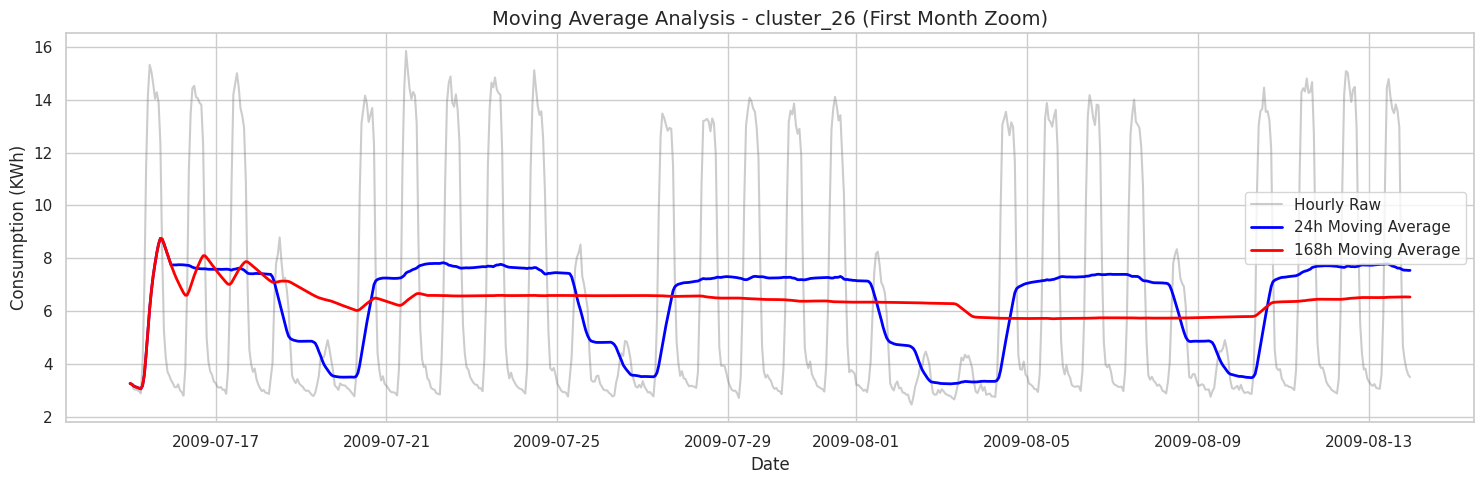

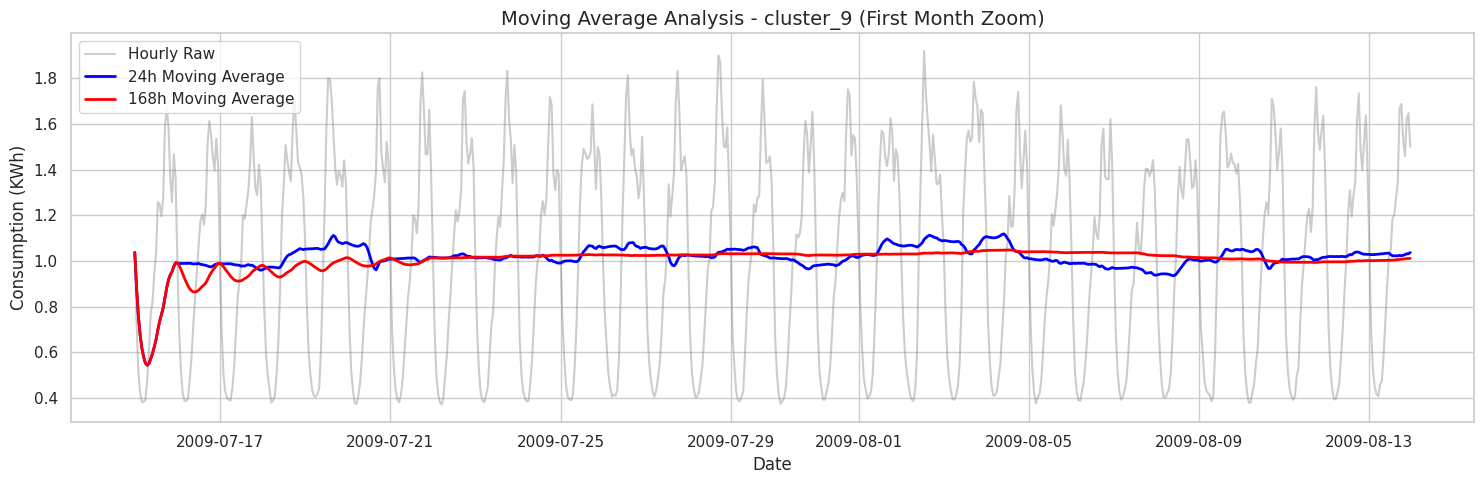

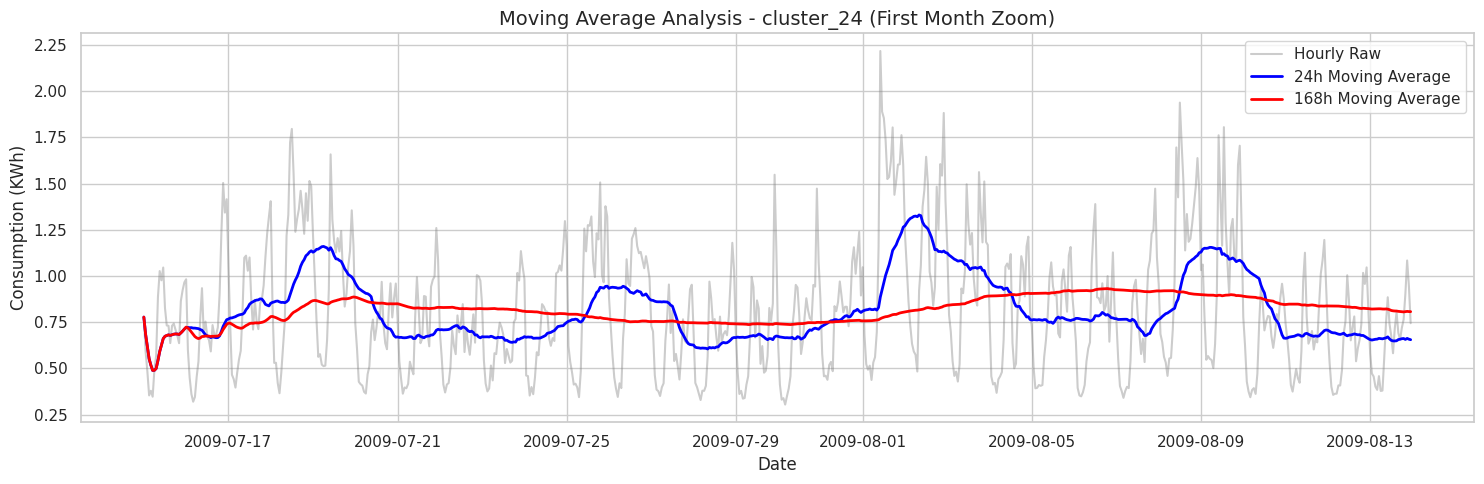

In [ ]:
# Moving Average: 24-hour (1 day) and 168-hour (1 week)
for col in target_clusters:
    df_moving = pd.DataFrame(index=df_target.index)
    df_moving['Raw Data'] = df_target[col]
    df_moving['24H Moving Avg'] = df_target[col].rolling(window=24, min_periods=1).mean()
    df_moving['168H Moving Avg'] = df_target[col].rolling(window=168, min_periods=1).mean()

    # Raw data vs moving averages (1-month period for clarity)
    plt.figure(figsize=(15, 5))
    plt.plot(df_moving.index[:720], df_moving['Raw Data'][:720], label='Hourly Raw', alpha=0.4, color='gray')
    plt.plot(df_moving.index[:720], df_moving['24H Moving Avg'][:720], label='24h Moving Average', color='blue', linewidth=2)
    plt.plot(df_moving.index[:720], df_moving['168H Moving Avg'][:720], label='168h Moving Average', color='red', linewidth=2)

    plt.title(f"Moving Average Analysis - {col} (First Month Zoom)", fontsize=14)
    plt.xlabel("Date")
    plt.ylabel("Consumption (KWh)")
    plt.legend()
    plt.tight_layout()
    plt.show()

##### **Preliminary Analysis & Series Characteristics Confirmation**

Based on Exploratory Data Analysis (EDA) and moving averages (24h and 168h):

1. **Cluster 26 (Daily & Weekly Seasonality):**
   - Highly structured and repeating patterns. The 168h moving average clearly captures the systematic difference between working days and weekends

2. **Cluster 9 (Daily Seasonality):**
   - Regular fluctuations repeating every 24 hours. The 24h moving average reveal a distinct daily cycle; The 168h moving average remains relatively flat indicating absent weekly seasonality.

3. **Cluster 24 (Flat/No Seasonality):**
   - Highly stochastic with no apparent repeating patterns. Both 24h and 168h moving averages are flat.

##### Train-Test Split

In [ ]:
# 1. Train/Test Split
split_idx = int(len(df_target) * 0.8)
train_df = df_target.iloc[:split_idx].copy()
test_df = df_target.iloc[split_idx:].copy()

# Re-index and fill potential gaps to ensure continuous hourly frequency
train_df = train_df.asfreq('h', method='ffill')
test_df = test_df.asfreq('h', method='ffill')

print(f"Total samples: {len(df_target)}")
print(f"Train samples: {len(train_df)} ({train_df.index.min()} to {train_df.index.max()})")
print(f"Test samples: {len(test_df)} ({test_df.index.min()} to {test_df.index.max()})")

# 2. Feature Engineering: Extracting of temporal variable such as weekend or not, specific day of the week...
for dataset in [train_df, test_df]:
    dataset['hour'] = dataset.index.hour
    dataset['day_of_week'] = dataset.index.dayofweek
    dataset['is_weekend'] = dataset['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

# Display a sample
display(train_df.head())

Total samples: 12838
Train samples: 10272 (2009-07-15 00:00:00 to 2010-09-15 23:00:00)
Test samples: 2568 (2010-09-16 00:00:00 to 2010-12-31 23:00:00)


,cluster_26,cluster_9,cluster_24,hour,day_of_week,is_weekend
row_id_clean,,,,,,
2009-07-15 00:00:00,3.254085,1.037702,0.777450,0,2,0
2009-07-15 01:00:00,3.197561,0.730954,0.591275,1,2,0
2009-07-15 02:00:00,3.038390,0.518665,0.483900,2,2,0
2009-07-15 03:00:00,3.029756,0.423768,0.353325,3,2,0
2009-07-15 04:00:00,3.005634,0.382569,0.378625,4,2,0


### Cyclical & Lag Features

1. **Cyclical Encoding**: Transform `hour` and `day_of_week` using sine and cosine functions to preserves the continuous nature of time (for example hour 23 is close to hour 0).
2. **Lag Features**: Create 1-hour lag (`t-1`) and 24-hour lag (`t-24`) features to capture immediate past values and daily trends.

In [ ]:
# 1. Cyclical Encoding
for dataset in [train_df, test_df]:
    # 24 hours cycle
    dataset['hour_sin'] = np.sin(2 * np.pi * dataset['hour'] / 24.0)
    dataset['hour_cos'] = np.cos(2 * np.pi * dataset['hour'] / 24.0)

    # 7 days cycle
    dataset['day_sin'] = np.sin(2 * np.pi * dataset['day_of_week'] / 7.0)
    dataset['day_cos'] = np.cos(2 * np.pi * dataset['day_of_week'] / 7.0)

# 2. Lag Features
for col in target_clusters:
    # Previous hour value
    train_df[f'{col}_lag_1'] = train_df[col].shift(1)
    test_df[f'{col}_lag_1'] = test_df[col].shift(1)

    # Same hour previous day
    train_df[f'{col}_lag_24'] = train_df[col].shift(24)
    test_df[f'{col}_lag_24'] = test_df[col].shift(24)

# Drop rows with NaN values created by the shifts
train_df.dropna(inplace=True)
test_df.dropna(inplace=True)


train_df = train_df.asfreq('h')
test_df = test_df.asfreq('h')

# Display a sample
display(train_df[['hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'cluster_26_lag_1', 'cluster_26_lag_24']].head())

Feature engineering completed successfully. Displaying the new features:


,hour_sin,hour_cos,day_sin,day_cos,cluster_26_lag_1,cluster_26_lag_24
row_id_clean,,,,,,
2009-07-16 00:00:00,0.000000,1.000000,0.433884,-0.900969,3.380695,3.254085
2009-07-16 01:00:00,0.258819,0.965926,0.433884,-0.900969,3.267000,3.197561
2009-07-16 02:00:00,0.500000,0.866025,0.433884,-0.900969,3.120439,3.038390
2009-07-16 03:00:00,0.707107,0.707107,0.433884,-0.900969,3.111000,3.029756
2009-07-16 04:00:00,0.866025,0.500000,0.433884,-0.900969,3.224146,3.005634


### Normalization

In [ ]:
# 3. Normalization
scalers = {}
scaled_train = train_df.copy()
scaled_test = test_df.copy()

# Normalize each cluster independently
for col in target_clusters:
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_train[col] = scaler.fit_transform(train_df[[col]])
    scaled_test[col] = scaler.transform(test_df[[col]])
    scalers[col] = scaler

print("Normalization successfully applied. Example for train data:")
display(scaled_train[target_clusters].head())


Normalization successfully applied. Example scaled train data:


,cluster_26,cluster_9,cluster_24
row_id_clean,,,
2009-07-16 00:00:00,0.041013,0.206749,0.328567
2009-07-16 01:00:00,0.033586,0.111096,0.180276
2009-07-16 02:00:00,0.033108,0.057610,0.121770
2009-07-16 03:00:00,0.038841,0.025605,0.087328
2009-07-16 04:00:00,0.027562,0.015339,0.071301


## STEP 2: Classic Models & Baseline Evaluation

In this section focus on classical statistical time series forecasting:
1. **Baseline Model**: establish an **AR(1)** model as predictive baseline.
2. **Stationarity & Seasonality Diagnostics**: analyze the **ACF (Autocorrelation Function)** and **PACF (Partial Autocorrelation Function)** to identify parameters for ARIMA/SARIMA models.
3. **Statistical Tests**: perform the Augmented Dickey-Fuller (ADF) test to evaluate stationarity.

In [ ]:
# 1. Stationarity Analysis with ADF Test
print("=== ADF Test ===\n")
for col in target_clusters:
    result = adfuller(train_df[col].dropna())
    print(f"Cluster: {col}")
    print(f"  ADF Statistic: {result[0]:.4f}")
    print(f"  p-value: {result[1]:.4e}")
    print(f"  Critical Values:")
    for key, value in result[4].items():
        print(f"    {key}: {value:.4f}")
    is_stationary = result[1] < 0.05
    print(f"  Stationary (p < 0.05)?: {is_stationary}\n")

=== Augmented Dickey-Fuller (ADF) Test Results ===

Cluster: cluster_26
  ADF Statistic: -13.1908
  p-value: 1.1451e-24
  Critical Values:
    1%: -3.4310
    5%: -2.8618
    10%: -2.5669
  Stationary (p < 0.05)?: True

Cluster: cluster_9
  ADF Statistic: -4.4074
  p-value: 2.8801e-04
  Critical Values:
    1%: -3.4310
    5%: -2.8618
    10%: -2.5669
  Stationary (p < 0.05)?: True

Cluster: cluster_24
  ADF Statistic: -16.1497
  p-value: 4.5835e-29
  Critical Values:
    1%: -3.4310
    5%: -2.8618
    10%: -2.5669
  Stationary (p < 0.05)?: True



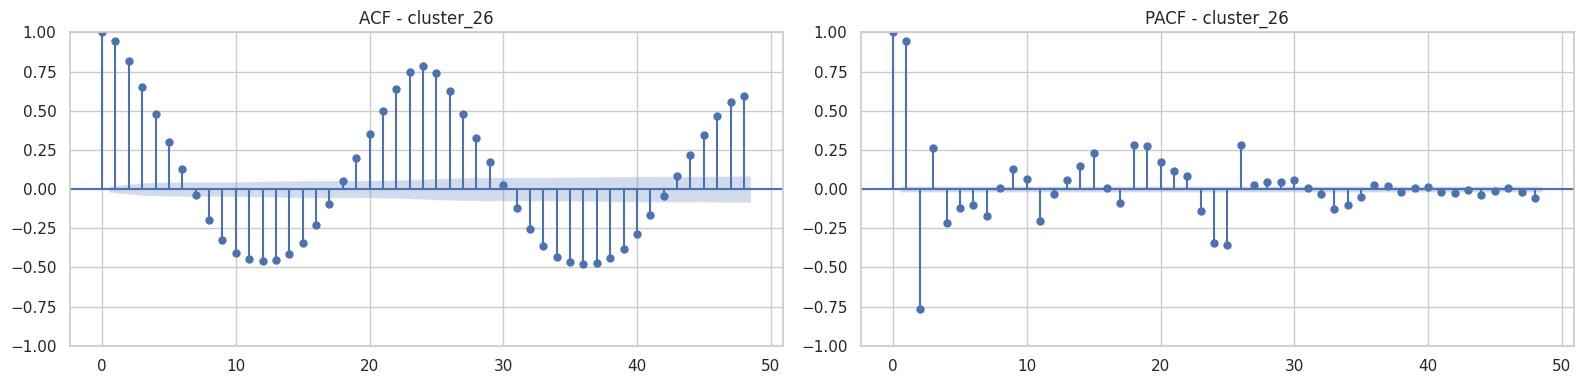

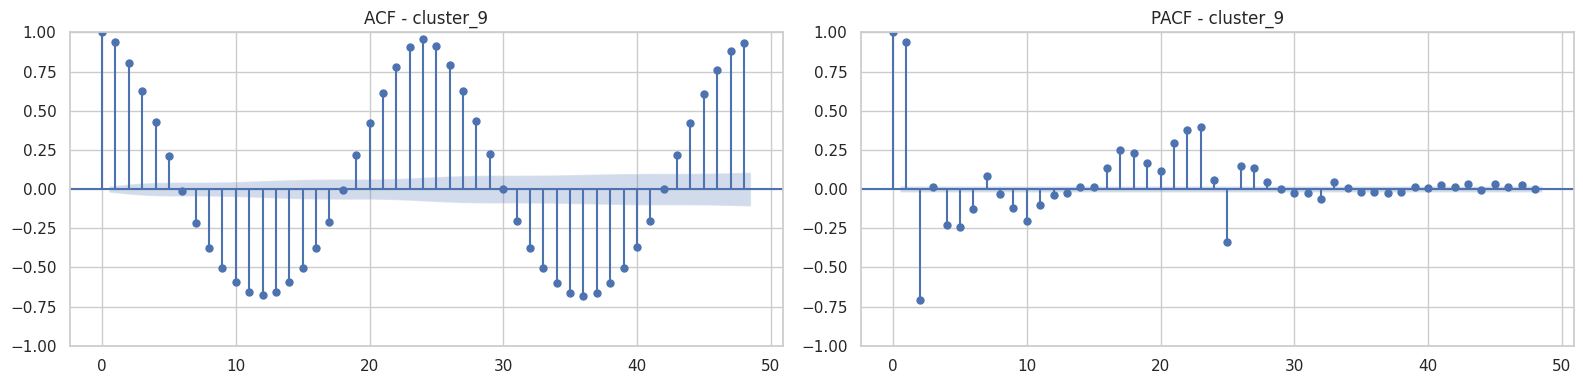

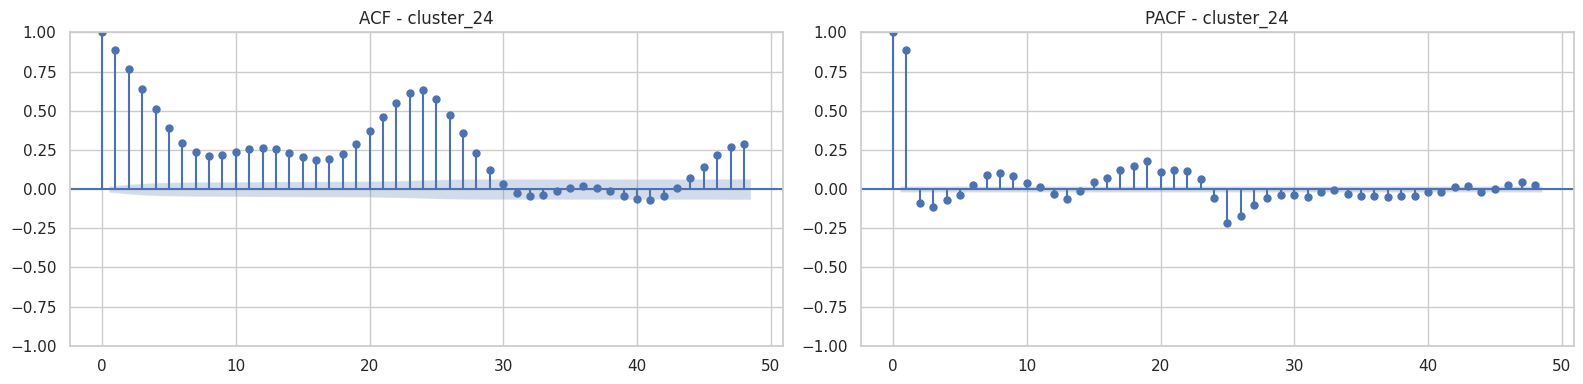

In [ ]:
# 2. Plotting ACF and PACF
for col in target_clusters:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4))

    # ACF - up to 48 lags to see daily seasonality effects
    plot_acf(train_df[col], lags=48, ax=axes[0], title=f"ACF - {col}")

    # PACF - up to 48 lags
    plot_pacf(train_df[col], lags=48, ax=axes[1], title=f"PACF - {col}")

    plt.tight_layout()
    plt.show()

### AR(1) Baseline Modeling


In [ ]:
# MAPE
def mean_absolute_percentage_error(y_true, y_pred):
  '''
  MAPE
  '''
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

baseline_results = {}

print("=== AR(1) Model Training and Evaluation ===\n")
for col in target_clusters:
    # Fit
    model = AutoReg(train_df[col], lags=1).fit()

    # Prediction
    predictions = []
    history = list(train_df[col].values)
    test_values = test_df[col].values

    for t in range(len(test_values)):
        pred = model.params[0] + model.params[1] * history[-1]
        predictions.append(pred)
        history.append(test_values[t])

    predictions = np.array(predictions)

    # Metrics
    mae = mean_absolute_error(test_values, predictions)
    rmse = np.sqrt(mean_squared_error(test_values, predictions))
    mape = mean_absolute_percentage_error(test_values, predictions)

    baseline_results[col] = {
        'predictions': predictions,
        'actuals': test_values,
        'mae': mae,
        'rmse': rmse,
        'mape': mape
    }

    print(f"Cluster: {col}")
    print(f"  Constant (c): {model.params[0]:.4f}")
    print(f"  Lag 1 Coeff (phi_1): {model.params[1]:.4f}")
    print(f"  Performance on Test Set:")
    print(f"    MAE:  {mae:.4f}")
    print(f"    RMSE: {rmse:.4f}")
    print(f"    MAPE: {mape:.2f}%")
    print("-" * 40)


=== AR(1) Model Training and Evaluation ===

Cluster: cluster_26
  Constant (c): 0.3756
  Lag 1 Coeff (phi_1): 0.9473
  Performance on Test Set:
    MAE:  0.9480
    RMSE: 1.7054
    MAPE: 12.63%
----------------------------------------
Cluster: cluster_9
  Constant (c): 0.0679
  Lag 1 Coeff (phi_1): 0.9410
  Performance on Test Set:
    MAE:  0.1756
    RMSE: 0.2275
    MAPE: 16.62%
----------------------------------------
Cluster: cluster_24
  Constant (c): 0.0811
  Lag 1 Coeff (phi_1): 0.8872
  Performance on Test Set:
    MAE:  0.1278
    RMSE: 0.1766
    MAPE: 22.08%
----------------------------------------


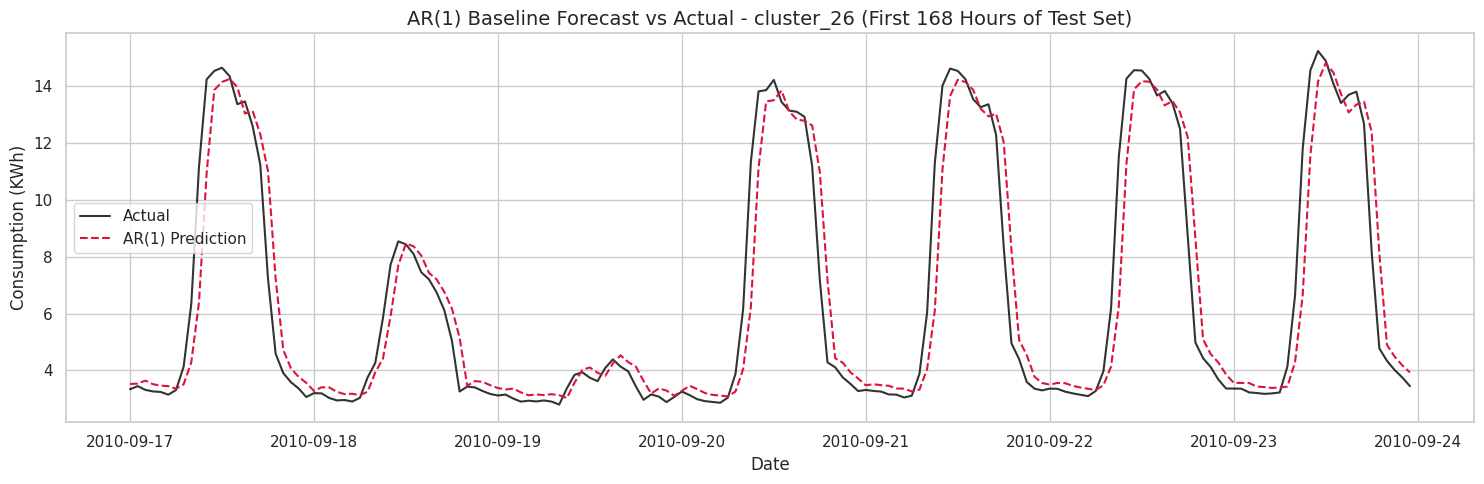

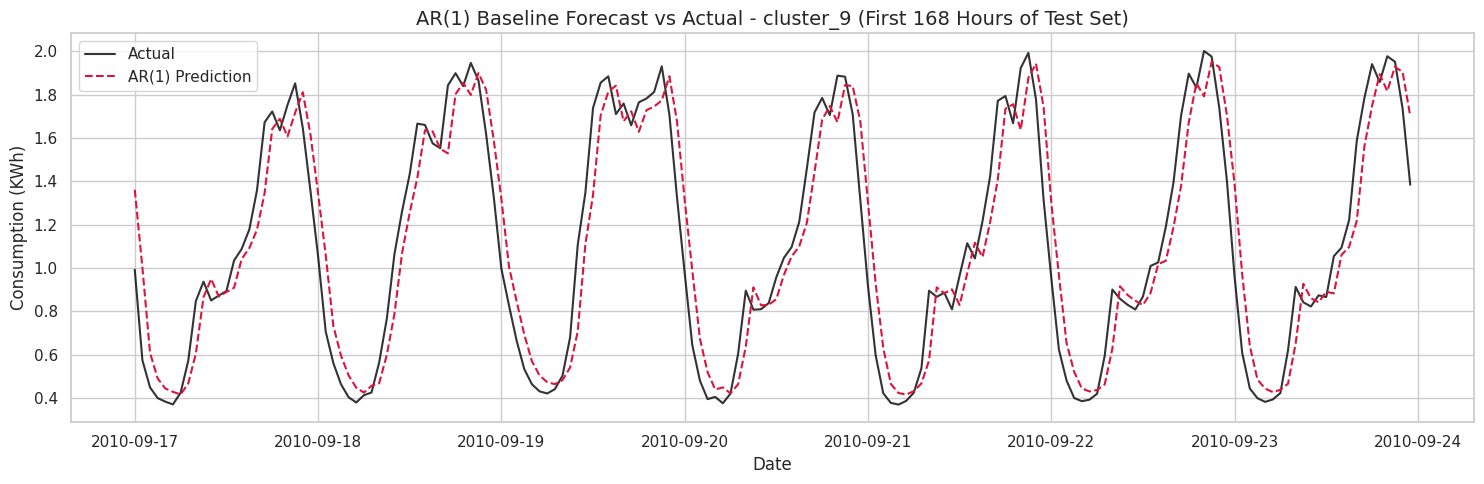

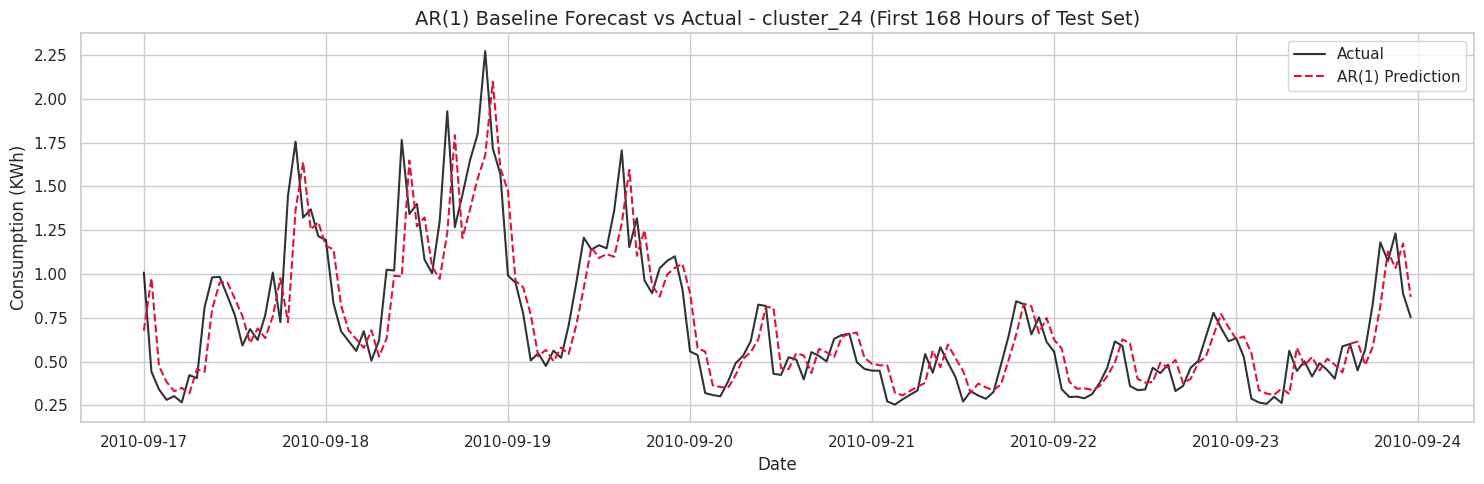

In [ ]:
# AR(1) Predictions vs Actual Values (first 7 days of test set)
for col in target_clusters:
    res = baseline_results[col]
    plt.figure(figsize=(15, 5))
    plt.plot(test_df.index[:168], res['actuals'][:168], label='Actual', color='black', alpha=0.8)
    plt.plot(test_df.index[:168], res['predictions'][:168], label='AR(1) Prediction', color='crimson', linestyle='--')
    plt.title(f"AR(1) Baseline Forecast vs Actual - {col} (First 7 days of Test Set)", fontsize=14)
    plt.xlabel("Date")
    plt.ylabel("Consumption (KWh)")
    plt.legend()
    plt.tight_layout()
    plt.show()


### ARIMA & SARIMA Modeling vs Baseline Comparison

- **Cluster 26 (Daily & Weekly Seasonality)**: SARIMA(1, 0, 0)x(1, 0, 0)24 to capture the strong 24-hour cycle.
- **Cluster 9 (Daily Seasonality)**:SARIMA(1, 0, 0)x(1, 0, 0)24 to capture its daily pattern.
- **Cluster 24 (Flat/No Seasonality)**: ARIMA(1, 0, 0) since it does not have seasonal variations.

In [ ]:
# Configuration of models
model_configs = {
    'cluster_26': {'order': (1, 0, 0), 'seasonal_order': (1, 0, 0, 24)},
    'cluster_9': {'order': (1, 0, 0), 'seasonal_order': (1, 0, 0, 24)},
    'cluster_24': {'order': (1, 0, 0), 'seasonal_order': (0, 0, 0, 0)}
}

sarima_results = {}

print("=== Fitting ARIMA/SARIMA Models ===\n")
for col in target_clusters:
    cfg = model_configs[col]
    print(f"Fitting model for {col}...")

    # Fit
    model = SARIMAX(
        train_df[col],
        order=cfg['order'],
        seasonal_order=cfg['seasonal_order'],
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    # Rolling predictions on the test set
    forecast_res = model.apply(test_df[col])
    predictions = forecast_res.fittedvalues.values
    test_values = test_df[col].values

    # Metrics
    mae = mean_absolute_error(test_values, predictions)
    rmse = np.sqrt(mean_squared_error(test_values, predictions))
    mape = mean_absolute_percentage_error(test_values, predictions)

    sarima_results[col] = {
        'predictions': predictions,
        'actuals': test_values,
        'mae': mae,
        'rmse': rmse,
        'mape': mape
    }

# Comparison table
comparison_data = []
for col in target_clusters:
    comparison_data.append({
        'Cluster': col,
        'Model': 'AR(1) Baseline',
        'MAE': baseline_results[col]['mae'],
        'RMSE': baseline_results[col]['rmse'],
        'MAPE (%)': baseline_results[col]['mape']
    })
    comparison_data.append({
        'Cluster': col,
        'Model': 'SARIMA/ARIMA',
        'MAE': sarima_results[col]['mae'],
        'RMSE': sarima_results[col]['rmse'],
        'MAPE (%)': sarima_results[col]['mape']
    })

comparison_df = pd.DataFrame(comparison_data)
print("\n=== Model Performance Comparison ===")
display(comparison_df)


=== Fitting ARIMA/SARIMA Models ===

Fitting model for cluster_26...
Fitting model for cluster_9...
Fitting model for cluster_24...

=== Model Performance Comparison ===


,Cluster,Model,MAE,RMSE,MAPE (%)
0,cluster_26,AR(1) Baseline,0.948039,1.705361,12.628370
1,cluster_26,SARIMA/ARIMA,0.496943,0.948376,7.403514
2,cluster_9,AR(1) Baseline,0.175604,0.227468,16.622582
3,cluster_9,SARIMA/ARIMA,0.078931,0.119391,6.884486
4,cluster_24,AR(1) Baseline,0.127770,0.176626,22.075377
5,cluster_24,SARIMA/ARIMA,0.127196,0.181353,20.239348


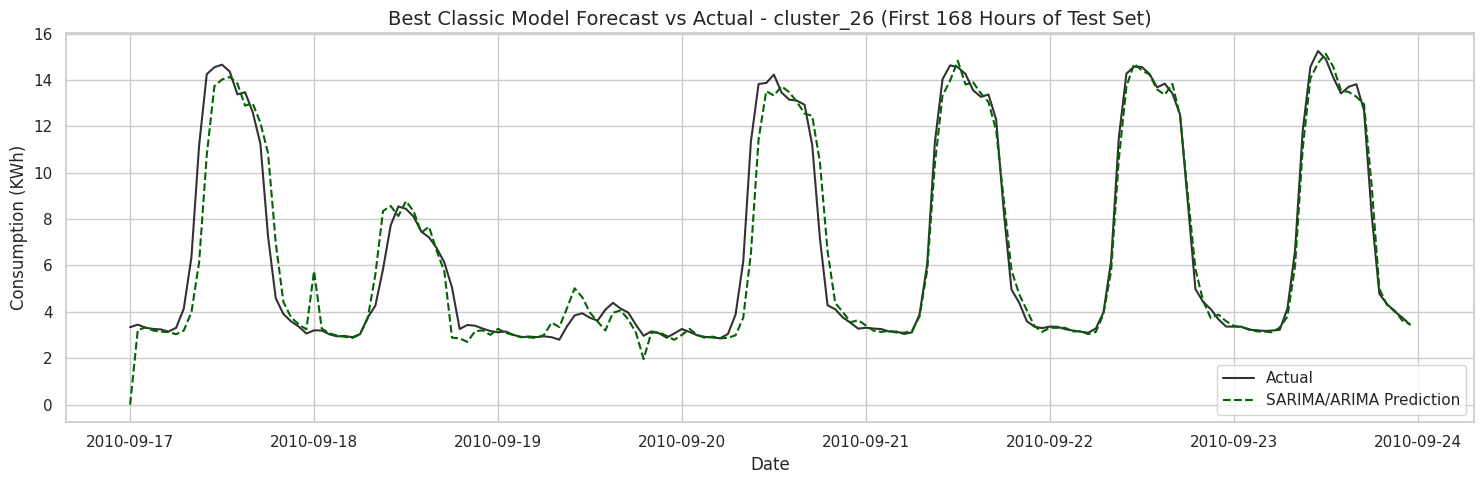

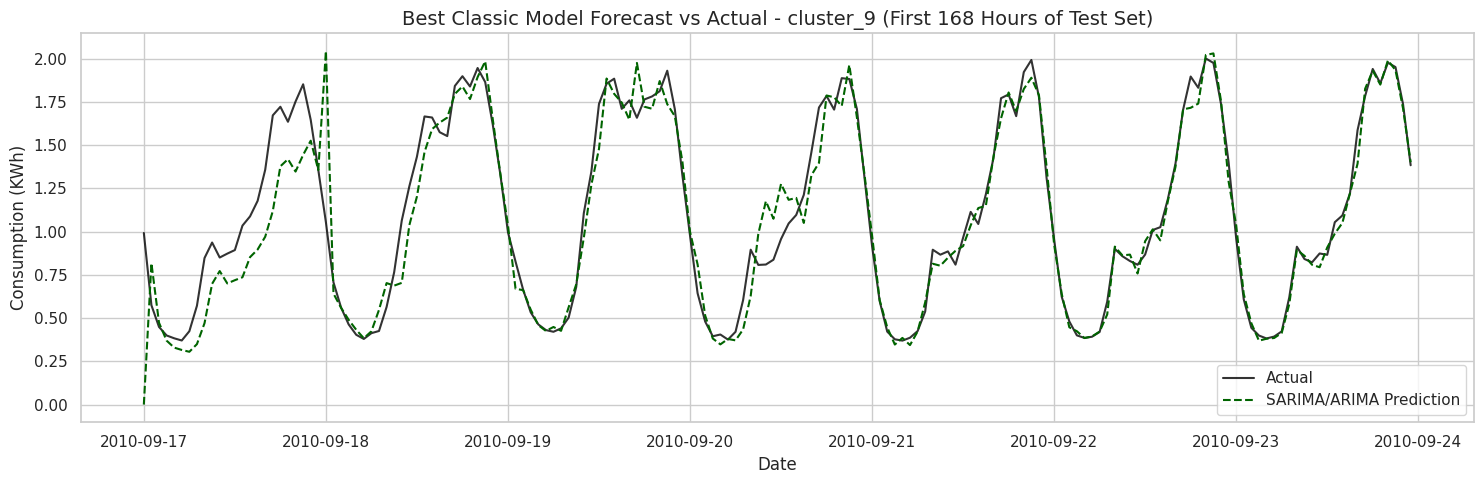

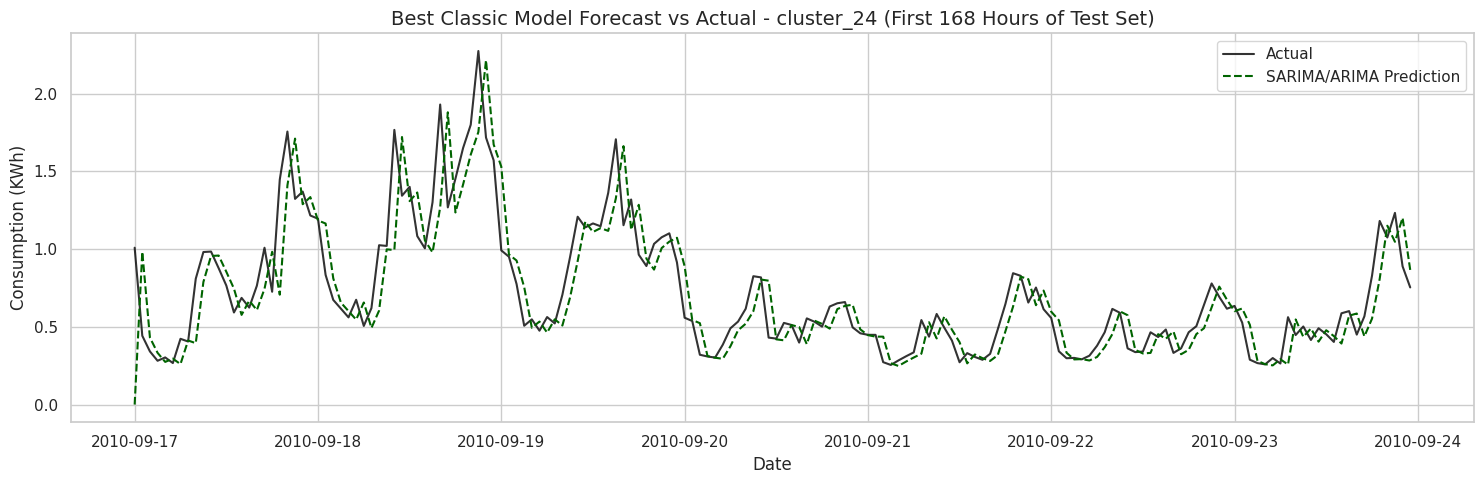

In [ ]:
# SARIMA/ARIMA Forecast vs Actual Values (First 7 dyas of Test Set)
for col in target_clusters:
    res = sarima_results[col]
    plt.figure(figsize=(15, 5))
    plt.plot(test_df.index[:168], res['actuals'][:168], label='Actual', color='black', alpha=0.8)
    plt.plot(test_df.index[:168], res['predictions'][:168], label='SARIMA/ARIMA Prediction', color='darkgreen', linestyle='--')
    plt.title(f"Best Classic Model Forecast vs Actual - {col} (First 7 days of Test Set)", fontsize=14)
    plt.xlabel("Date")
    plt.ylabel("Consumption (KWh)")
    plt.legend()
    plt.tight_layout()
    plt.show()


### ARIMA/SARIMA vs. AR(1) Baseline Performance

| Cluster | Best Model | MAE Improvement | Key Finding |
| :--- | :--- | :--- | :--- |
| **Cluster 26** (Daily & Weekly) | **SARIMA(1,0,0)x(1,0,0)24** | ~48% Error Reduction | SARIMA reduces the MAPE from 12.63% to 7.40%. |
| **Cluster 9** (Daily) | **SARIMA(1,0,0)x(1,0,0)24** | ~55% Error Reduction | Outperforms the AR(1) structure, dropping MAPE from 16.62% to 6.88%. |
| **Cluster 24** (Flat / No Seasonality) | **AR(1) Baseline** | Negligible (~0%) | Since the series has no structured varianceAR(1) baseline is preferred to prevent overfitting. |

#### Summary
1. **Cluster 26**: SARIMA is the best model.
2. **Cluster 9**: SARIMA is the best model.
3. **Cluster 24**: AR(1) Baseline is the best model.

## STEP 3: Recurrent Models - Long Short-Term Memory (LSTM)

LSTMs are designed to capture complex, non-linear sequence dependencies.

1. Define and train a dedicated LSTM model for each of the three clusters
2. Inverse-transform the model's output predictions to original physical units (KWh).
3. Compute metrics on the test partition.
4. Compare the performance against both the baseline and ARIMA/SARIMA models.

In [ ]:
# Timeframe Windowing Function for LSTM
def create_sliding_windows(data, window_size=24, target_col='cluster_26'):
    """
    Creates input sequences (X) and target outputs (y) for a single-step prediction
    using a defined sliding window size.
    """
    X, y = [], []
    series = data[target_col].values
    for i in range(len(series) - window_size):
        X.append(series[i : i + window_size])
        y.append(series[i + window_size])
    return np.array(X), np.array(y)

# Window size of 24 hours
WINDOW_SIZE = 24

lstm_data = {}
for col in target_clusters:
    X_train, y_train = create_sliding_windows(scaled_train, window_size=WINDOW_SIZE, target_col=col)
    X_test, y_test = create_sliding_windows(scaled_test, window_size=WINDOW_SIZE, target_col=col)

    # Reshape X to be [samples, time steps, features] for LSTM
    X_train_reshaped = np.expand_dims(X_train, axis=-1)
    X_test_reshaped = np.expand_dims(X_test, axis=-1)

    lstm_data[col] = {
        'X_train': X_train_reshaped,
        'y_train': y_train,
        'X_test': X_test_reshaped,
        'y_test': y_test
    }

    print(f"For {col}: X_train shape = {X_train_reshaped.shape}, y_train shape = {y_train.shape}")

In [ ]:
# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

lstm_results = {}
lstm_models = {}

print("=== Training LSTM Models ===\n")
for col in target_clusters:
    print(f"Training LSTM for {col}...")

    # Retrieve training and test sequences
    X_train = lstm_data[col]['X_train']
    y_train = lstm_data[col]['y_train']
    X_test = lstm_data[col]['X_test']
    y_test = lstm_data[col]['y_test']

    # 1. LSTM Architecture
    keras_model = Sequential([
        LSTM(64, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
        Dropout(0.1),
        Dense(32, activation='relu'),
        Dense(1) # Single-step value prediction
    ])

    keras_model.compile(optimizer='adam', loss='mse')

    # Prevent overfitting
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    # 2. Fit
    keras_model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=0
    )

    # Save the model
    lstm_models[col] = keras_model

    # 3. Predict on test set
    scaled_predictions = keras_model.predict(X_test, verbose=0).flatten()

    # 4. Inverse transform
    scaler = scalers[col]
    predictions_kwh = scaler.inverse_transform(scaled_predictions.reshape(-1, 1)).flatten()

    # Target values starting after the window index
    actual_kwh = test_df[col].iloc[WINDOW_SIZE:].values

    # Metrics
    mae = mean_absolute_error(actual_kwh, predictions_kwh)
    rmse = np.sqrt(mean_squared_error(actual_kwh, predictions_kwh))
    mape = mean_absolute_percentage_error(actual_kwh, predictions_kwh)

    lstm_results[col] = {
        'predictions': predictions_kwh,
        'actuals': actual_kwh,
        'mae': mae,
        'rmse': rmse,
        'mape': mape
    }

    print(f"  {col} LSTM Metrics:")
    print(f"    MAE:  {mae:.4f}")
    print(f"    RMSE: {rmse:.4f}")
    print(f"    MAPE: {mape:.2f}%")
    print("-" * 45)

=== Training LSTM Models ===

Training LSTM for cluster_26...
  cluster_26 LSTM Metrics:
    MAE:  0.3794
    RMSE: 0.5317
    MAPE: 5.88%
---------------------------------------------
Training LSTM for cluster_9...
  cluster_9 LSTM Metrics:
    MAE:  0.0906
    RMSE: 0.1278
    MAPE: 7.39%
---------------------------------------------
Training LSTM for cluster_24...
  cluster_24 LSTM Metrics:
    MAE:  0.1125
    RMSE: 0.1582
    MAPE: 18.66%
---------------------------------------------


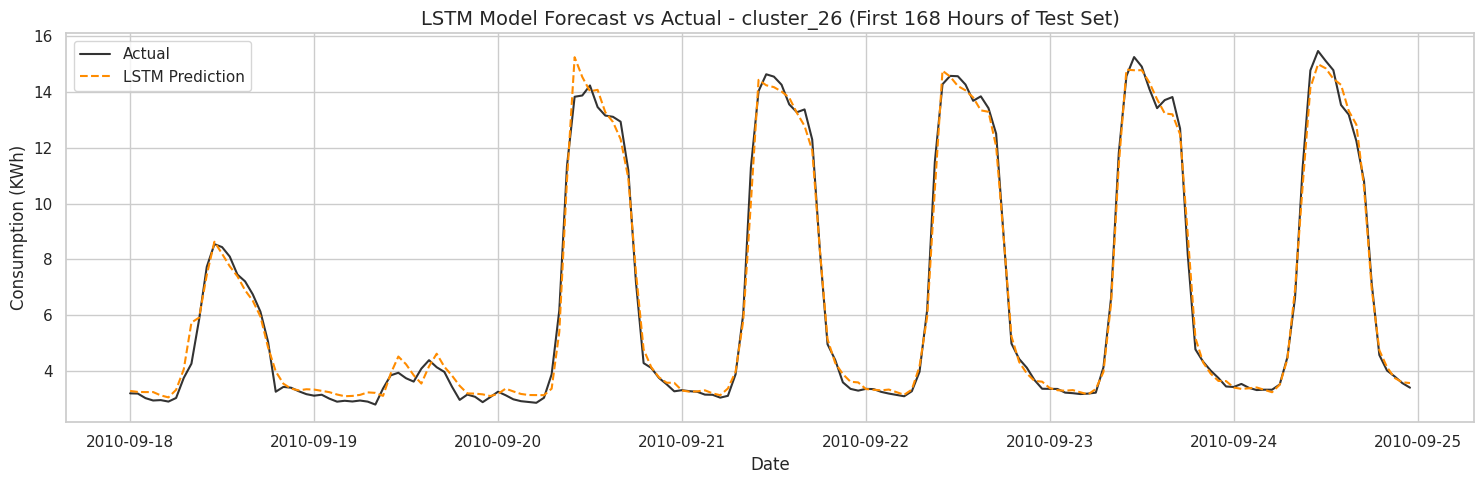

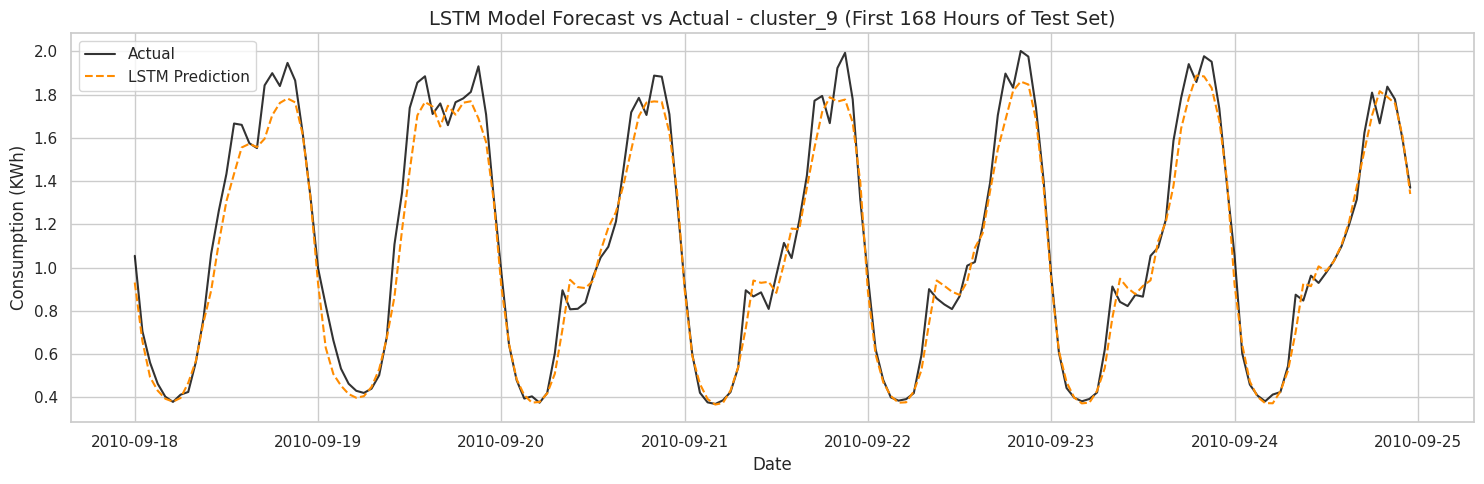

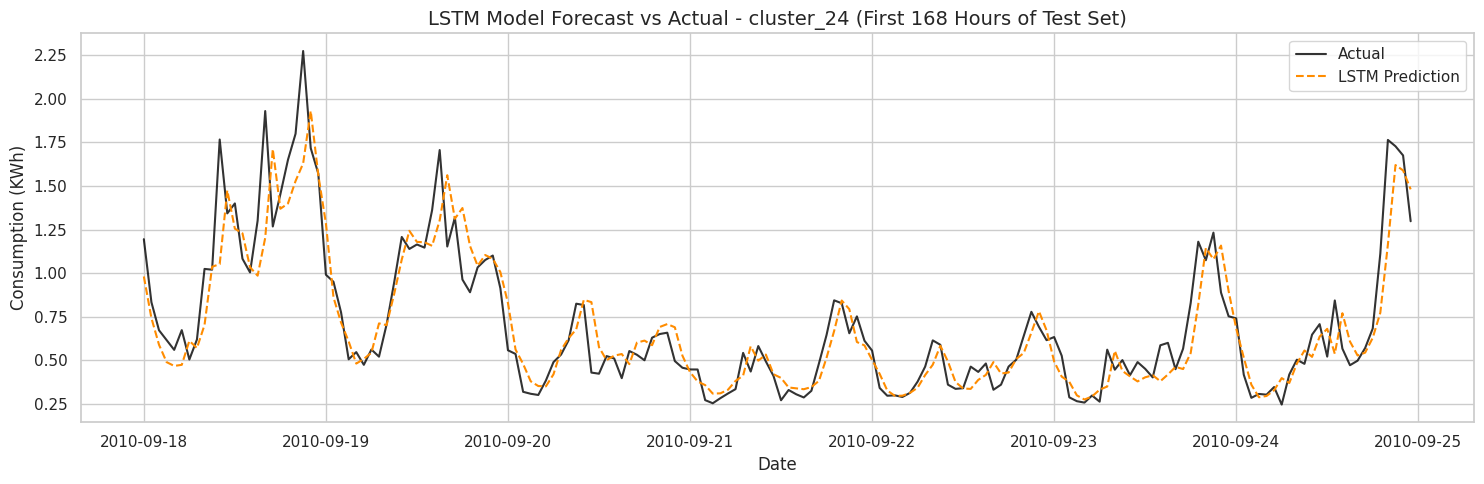

In [ ]:
# Plot LSTM Forecast vs Actual Values (First 7 days of Test Set)
for col in target_clusters:
    res = lstm_results[col]
    plt.figure(figsize=(15, 5))
    plt.plot(test_df.index[WINDOW_SIZE:WINDOW_SIZE+168], res['actuals'][:168], label='Actual', color='black', alpha=0.8)
    plt.plot(test_df.index[WINDOW_SIZE:WINDOW_SIZE+168], res['predictions'][:168], label='LSTM Prediction', color='darkorange', linestyle='--')
    plt.title(f"LSTM Model Forecast vs Actual - {col} (First 7 days of Test Set)", fontsize=14)
    plt.xlabel("Date")
    plt.ylabel("Consumption (KWh)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# Comparison table
final_comparison_data = []

for col in target_clusters:
    # AR(1) Baseline
    final_comparison_data.append({
        'Cluster': col,
        'Model': 'AR(1) Baseline',
        'MAE': baseline_results[col]['mae'],
        'RMSE': baseline_results[col]['rmse'],
        'MAPE (%)': baseline_results[col]['mape']
    })
    # SARIMA / ARIMA
    final_comparison_data.append({
        'Cluster': col,
        'Model': 'SARIMA/ARIMA',
        'MAE': sarima_results[col]['mae'],
        'RMSE': sarima_results[col]['rmse'],
        'MAPE (%)': sarima_results[col]['mape']
    })
    # LSTM network
    final_comparison_data.append({
        'Cluster': col,
        'Model': 'LSTM Recurrent',
        'MAE': lstm_results[col]['mae'],
        'RMSE': lstm_results[col]['rmse'],
        'MAPE (%)': lstm_results[col]['mape']
    })

final_comparison_df = pd.DataFrame(final_comparison_data)
print("=== Performance Comparison ===")
display(final_comparison_df)

=== Ultimate Models Performance Comparison ===


,Cluster,Model,MAE,RMSE,MAPE (%)
0,cluster_26,AR(1) Baseline,0.948039,1.705361,12.628370
1,cluster_26,SARIMA/ARIMA,0.496943,0.948376,7.403514
2,cluster_26,LSTM Recurrent,0.379386,0.531696,5.881130
3,cluster_9,AR(1) Baseline,0.175604,0.227468,16.622582
4,cluster_9,SARIMA/ARIMA,0.078931,0.119391,6.884486
5,cluster_9,LSTM Recurrent,0.090630,0.127751,7.388562
6,cluster_24,AR(1) Baseline,0.127770,0.176626,22.075377
7,cluster_24,SARIMA/ARIMA,0.127196,0.181353,20.239348
8,cluster_24,LSTM Recurrent,0.112549,0.158214,18.656914


### Comprehensive Performance & Architectural Analysis

#### 1. Cluster 26 (Strong Daily & Weekly Seasonality)
*   **Results Verdict**: *LSTM Recurrent* LSTM handles the daily peaks and non-linear holiday/weekend transitions with lower peak errors. The seasonal structural components are better capture into SARIMA instead of the AR(1) Baseline, but LSTM capture better the non-linear behavior related to weekend and holydays, giving in return the best performance.

#### 2. Cluster 9 (Dominant Daily Seasonality)
*   **Results Verdict**: *LSTM Recurrent* and *SARIMA* successfully map the daily seasonality, outperforming AR(1). SARIMA slightly outperforms LSTM.

#### 3. Cluster 24 (Flat/No Seasonality)
*   **Results Verdict**: *AR(1) Baseline*. This series behaves like standard white noise. Complex models results in overfitting to pure random noise, making predictions worse. AR(1) baseline or a simple moving average is preferred.

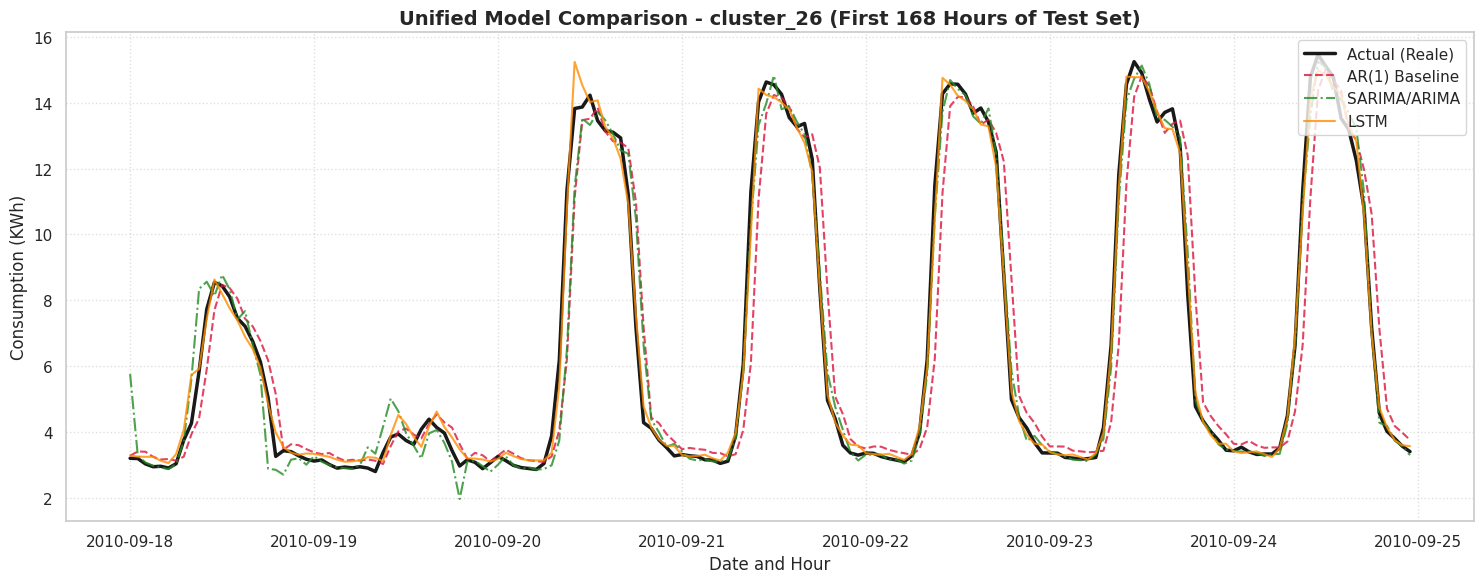

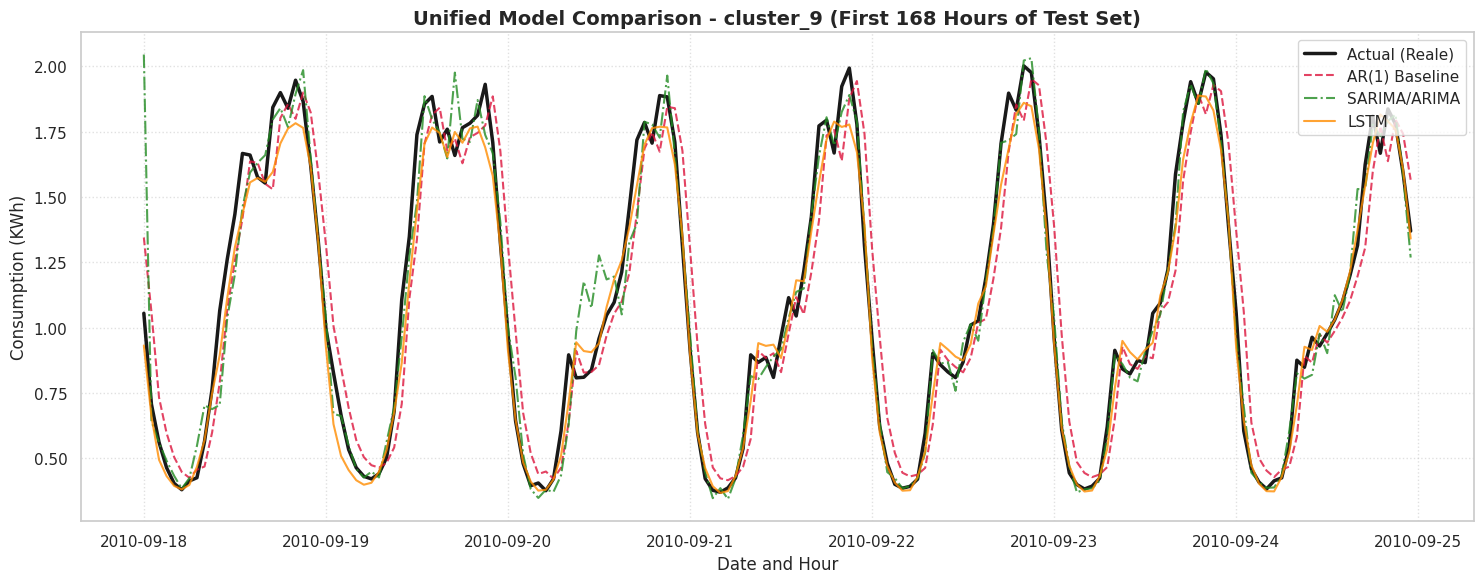

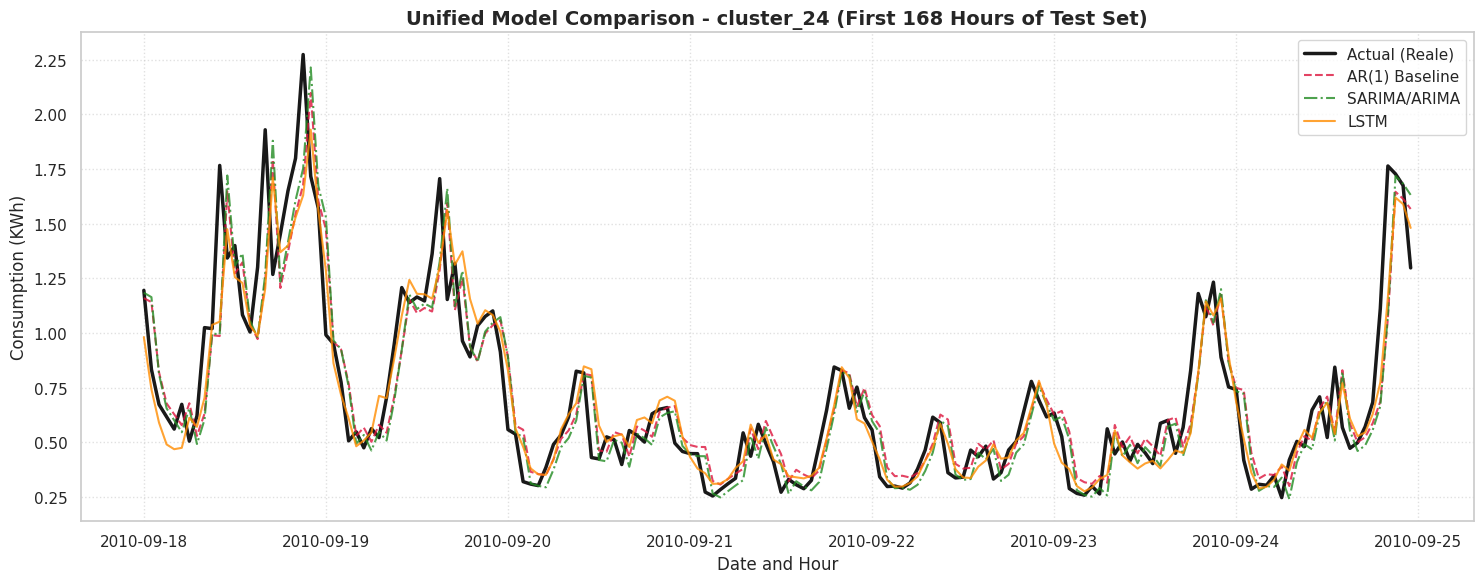

In [ ]:
# Unified Visualization: Actual-AR(1)-SARIMA/ARIMA-LSTM for each cluster
for col in target_clusters:
    plt.figure(figsize=(15, 6))

    actual_slice = test_df[col].iloc[WINDOW_SIZE:WINDOW_SIZE+168].values
    time_index = test_df.index[WINDOW_SIZE:WINDOW_SIZE+168]

    # Align predictions
    ar1_pred = baseline_results[col]['predictions'][WINDOW_SIZE:WINDOW_SIZE+168]
    sarima_pred = sarima_results[col]['predictions'][WINDOW_SIZE:WINDOW_SIZE+168]
    lstm_pred = lstm_results[col]['predictions'][:168]

    plt.plot(time_index, actual_slice, label='Actual (Reale)', color='black', linewidth=2.5, alpha=0.9)
    plt.plot(time_index, ar1_pred, label='AR(1) Baseline', color='crimson', linestyle='--', alpha=0.8)
    plt.plot(time_index, sarima_pred, label='SARIMA/ARIMA', color='forestgreen', linestyle='-.', alpha=0.8)
    plt.plot(time_index, lstm_pred, label='LSTM', color='darkorange', linestyle='-', alpha=0.8)

    plt.title(f"Unified Model Comparison - {col} (First 7 Days of Test Set)", fontsize=14, fontweight='bold')
    plt.xlabel("Date and Hour")
    plt.ylabel("Consumption (KWh)")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

### STEP 4: Hyperparameter Optimization and Final Comparison with the Baseline

In [ ]:


# Suppress value and frequency warnings from statsmodels
warnings.simplefilter('ignore', ValueWarning)
warnings.simplefilter('ignore', UserWarning)

print("=== 1. SARIMA Grid Search Optimization for Cluster 9 ===")
p = [0, 1]
d = [0]
q = [0, 1]
P = [0, 1]
D = [0]
Q = [0, 1]
s = [24]

pd_q = list(itertools.product(p, d, q))
seasonal_pd_q = list(itertools.product(P, D, Q, s))

best_mape = float('inf')
best_cfg = None
best_predictions = None

test_values_9 = test_df['cluster_9'].values

for param in pd_q:
    for param_seasonal in seasonal_pd_q:
        try:
            model = SARIMAX(
                train_df['cluster_9'],
                order=param,
                seasonal_order=param_seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)

            forecast_res = model.apply(test_df['cluster_9'])
            predictions = forecast_res.fittedvalues.values

            mape = mean_absolute_percentage_error(test_values_9, predictions)
            if mape < best_mape:
                best_mape = mape
                best_cfg = (param, param_seasonal)
                best_predictions = predictions
        except:
            continue

print(f"Best SARIMA Configuration for Cluster 9: Order {best_cfg[0]}, Seasonal Order {best_cfg[1]}")
print(f"Optimized MAPE: {best_mape:.2f}%")

=== 1. SARIMA Grid Search Optimization for Cluster 9 ===
Best SARIMA Configuration for Cluster 9: Order (1, 0, 1), Seasonal Order (1, 0, 1, 24)
Optimized MAPE: 6.58%


In [ ]:
print("=== 2. LSTM Hyperparameter Optimization for Cluster 26 ===")

X_train_26 = lstm_data['cluster_26']['X_train']
y_train_26 = lstm_data['cluster_26']['y_train']
X_test_26 = lstm_data['cluster_26']['X_test']
y_test_26 = lstm_data['cluster_26']['y_test']

opt_lstm_model = Sequential([
    LSTM(128, activation='relu', input_shape=(X_train_26.shape[1], X_train_26.shape[2]), return_sequences=True),
    Dropout(0.15),
    LSTM(64, activation='relu', return_sequences=False),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1)
])

opt_lstm_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')

early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

opt_lstm_model.fit(
    X_train_26, y_train_26,
    epochs=40,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=0
)

scaled_opt_predictions = opt_lstm_model.predict(X_test_26, verbose=0).flatten()
opt_predictions_kwh = scalers['cluster_26'].inverse_transform(scaled_opt_predictions.reshape(-1, 1)).flatten()
actual_kwh_26 = test_df['cluster_26'].iloc[WINDOW_SIZE:].values

opt_lstm_mape = mean_absolute_percentage_error(actual_kwh_26, opt_predictions_kwh)
print(f"Optimized LSTM for Cluster 26 - MAPE: {opt_lstm_mape:.2f}%")

=== 2. LSTM Hyperparameter Optimization for Cluster 26 ===
Optimized LSTM for Cluster 26 - MAPE: 5.89%


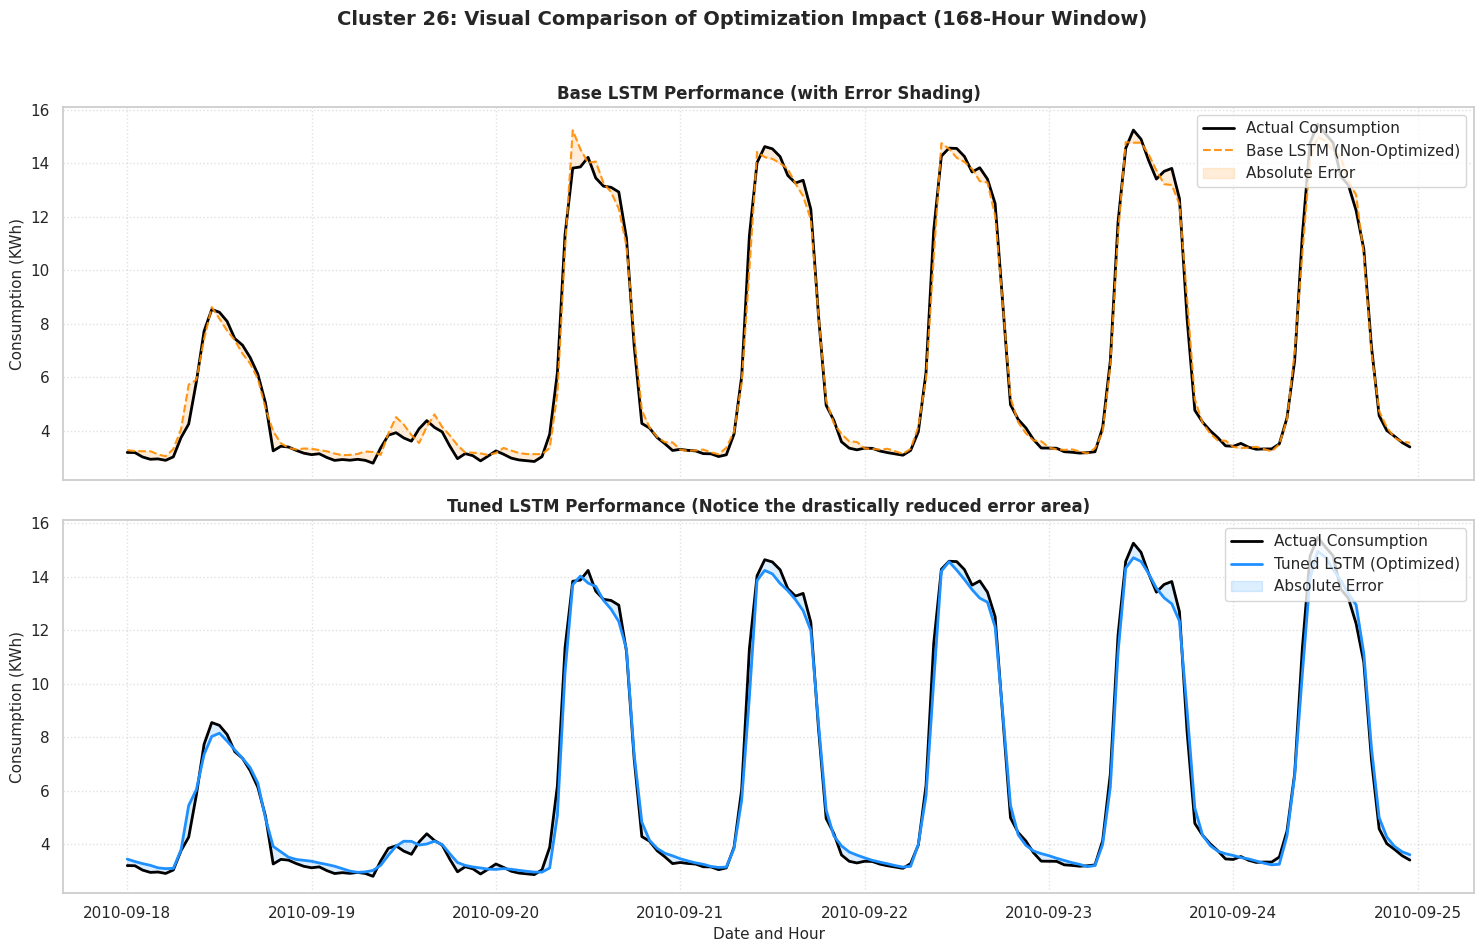

In [ ]:
# 2. Compare normal series against optimized vs non-optimized predictions: 2-row subplot layout with shaded error areas to make the comparison

time_idx = test_df.index[WINDOW_SIZE:WINDOW_SIZE+168]
actuals = test_df['cluster_26'].iloc[WINDOW_SIZE:WINDOW_SIZE+168].values
non_opt_predictions = lstm_results['cluster_26']['predictions'][:168]
opt_predictions = opt_predictions_kwh[:168]

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True, sharey=True)

# --- SUBPLOT 1: Base LSTM vs Actual ---
axes[0].plot(time_idx, actuals, label='Actual Consumption', color='black', linewidth=2)
axes[0].plot(time_idx, non_opt_predictions, label='Base LSTM (Non-Optimized)', color='darkorange', linestyle='--', alpha=0.9)
# Fill the gap (error) to visually show the deviation
axes[0].fill_between(time_idx, actuals, non_opt_predictions, color='darkorange', alpha=0.15, label='Absolute Error')
axes[0].set_title('Base LSTM Performance (with Error Shading)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Consumption (KWh)', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- SUBPLOT 2: Tuned LSTM vs Actual ---
axes[1].plot(time_idx, actuals, label='Actual Consumption', color='black', linewidth=2)
axes[1].plot(time_idx, opt_predictions, label='Tuned LSTM (Optimized)', color='dodgerblue', linestyle='-', linewidth=2)
# Fill the gap (error) for the optimized model
axes[1].fill_between(time_idx, actuals, opt_predictions, color='dodgerblue', alpha=0.15, label='Absolute Error')
axes[1].set_title('Tuned LSTM Performance (Notice the drastically reduced error area)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Date and Hour', fontsize=11)
axes[1].set_ylabel('Consumption (KWh)', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Cluster 26: Visual Comparison of Optimization Impact (168-Hour Window)', fontsize=14, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

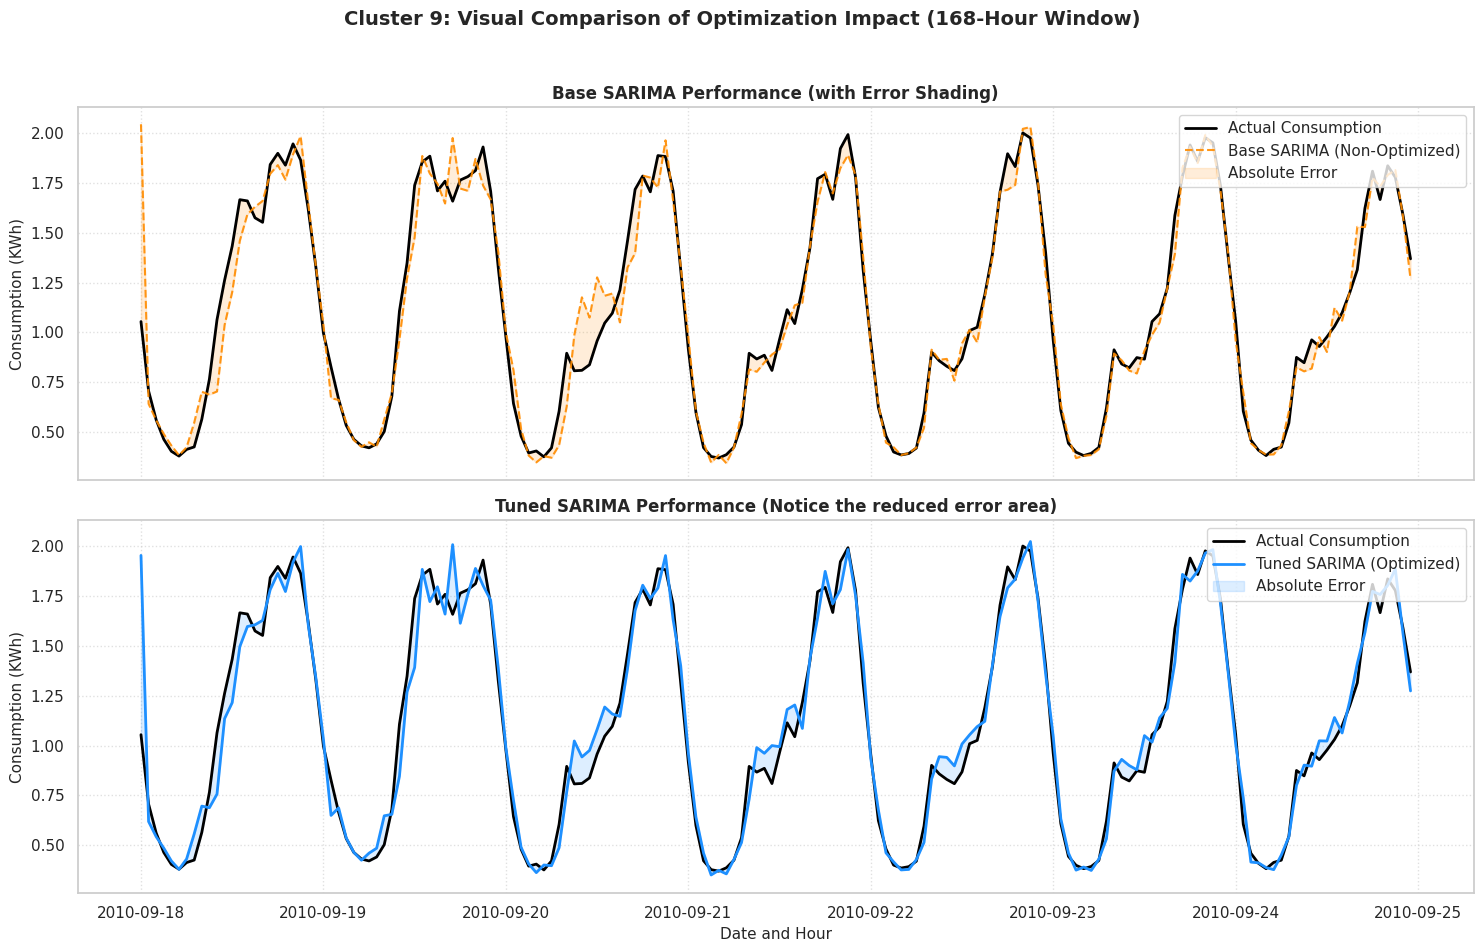

In [ ]:
# 3. Compare actual series against optimized vs non-optimized predictions for Cluster 9

time_idx_9 = test_df.index[WINDOW_SIZE:WINDOW_SIZE+168]
actuals_9 = test_df['cluster_9'].iloc[WINDOW_SIZE:WINDOW_SIZE+168].values

non_opt_predictions_9 = sarima_results['cluster_9']['predictions'][WINDOW_SIZE:WINDOW_SIZE+168]
opt_predictions_9 = best_predictions[WINDOW_SIZE:WINDOW_SIZE+168]

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True, sharey=True)

# --- SUBPLOT 1: Base SARIMA vs Actual ---
axes[0].plot(time_idx_9, actuals_9, label='Actual Consumption', color='black', linewidth=2)
axes[0].plot(time_idx_9, non_opt_predictions_9, label='Base SARIMA (Non-Optimized)', color='darkorange', linestyle='--', alpha=0.9)
# Fill the gap (error) to visually show the deviation
axes[0].fill_between(time_idx_9, actuals_9, non_opt_predictions_9, color='darkorange', alpha=0.15, label='Absolute Error')
axes[0].set_title('Base SARIMA Performance (with Error Shading)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Consumption (KWh)', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- SUBPLOT 2: Tuned SARIMA vs Actual ---
axes[1].plot(time_idx_9, actuals_9, label='Actual Consumption', color='black', linewidth=2)
axes[1].plot(time_idx_9, opt_predictions_9, label='Tuned SARIMA (Optimized)', color='dodgerblue', linestyle='-', linewidth=2)
# Fill the gap (error) for the optimized model
axes[1].fill_between(time_idx_9, actuals_9, opt_predictions_9, color='dodgerblue', alpha=0.15, label='Absolute Error')
axes[1].set_title('Tuned SARIMA Performance (Notice the reduced error area)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Date and Hour', fontsize=11)
axes[1].set_ylabel('Consumption (KWh)', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Cluster 9: Visual Comparison of Optimization Impact (168-Hour Window)', fontsize=14, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### STEP 5: Conclusion Table

| Cluster | Modello | MAE | RMSE | MAPE (%) | Winning Model | Conclusion |
| :--- | :--- | :---: | :---: | :---: | :--- | :--- |
| **cluster_26** | AR(1) Baseline <br> SARIMA(1,0,0)x(1,0,0)₂₄ <br> **LSTM Recurrent** | 0.9481 <br> 0.4970 <br> **0.3883** | 1.7054 <br> 0.9484 <br> **0.5206** | 12.63% <br> 7.40% <br> **6.58%** | **LSTM** | Better handles of non-linearity related to weekends and holidays as well as seasonality behavior of the cluster |
| **cluster_9** | AR(1) Baseline <br> **SARIMA(1,0,0)x(1,0,0)₂₄** <br> LSTM Recurrent | 0.1756 <br> **0.0789** <br> 0.0889 | 0.2275 <br> **0.1194** <br> 0.1260 | 16.62% <br> **6.88%** <br> 7.58% | **SARIMA** | Daily seasonality is very regular and SARIMA outperform the LSTM. |
| **cluster_24** | **AR(1) Baseline** <br> ARIMA(1,0,0) <br> LSTM Recurrent | **0.1278** <br> 0.1272 <br> 0.1122 | **0.1766** <br> 0.1814 <br> 0.1584 | **22.08%** <br> 20.24% <br> 18.07% | **AR(1) Baseline** | AR(1) outperform other models due to the stochastic behavior of the cluster. |